**ASSIGNMENT - 3 (Comparison)**

# LSTM vs LSTM + Attention: Sentiment Analysis on the US Airline Tweets Dataset (10-Fold Cross Validation)

This notebook compares the two Experiment 3 models:

| Model | Source notebook | Architecture |
|---|---|---|
| **LSTM** | `exp3/lstm_usairlinetweets.ipynb` | Embedding → SpatialDropout1D → BiLSTM(64) → Dropout(0.7) → Dense(3) |
| **LSTM + Attention** | `exp3/lstm_attention_usairlinetweets.ipynb` | Embedding → SpatialDropout1D → BiLSTM(64, return_sequences) → AttentionPooling(64) → Dropout(0.5) → Dense(3) |

Both models use **the same text cleaning, tokenizer, vocabulary size, sequence length, optimizer and callbacks**.
The only difference is the attention layer, so any gap in performance comes from attention.

Instead of a single 60:20:20 split, every model is evaluated with **stratified 10-fold cross validation**:

* The data is split into 10 stratified folds. Each fold is the **test set** exactly once.
* The other 9 folds are the training data. 10% of them is held out as a **validation set** for EarlyStopping / ReduceLROnPlateau.
* The tokenizer is fit **only on the training part of each fold**, so no test words leak into the vocabulary.
* Both models see **exactly the same folds and the same random seed** for each fold, so the 10 scores are paired.

The 10 test-fold scores per model are then compared with **box plots**, a fold-by-fold plot, paired statistical tests and pooled confusion matrices.

After that, both models also get a **hold-out test** (trained once on 80%, tested on the unseen 20%) and **fold-by-fold scatter plots**. **Part 2** adds the Experiment 1 models (MLP and CNN on MNIST) and **Part 3** the Experiment 2 models (LSTM oil-temperature forecasting on ETTh1, with data-exploration plots), each with 10-fold CV, box plots, significance tests, scatter plots and a hold-out test.

In [1]:
%pip install -q tensorflow numpy pandas matplotlib scikit-learn scipy kagglehub


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /home/rito/ju_lab/ks_lab/exp3/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## Hyperparameters

In [2]:
# Text preprocessing (same as exp3)
vocab_size = 10000
max_length = 40
embedding_dim = 128

# Training (same as exp3)
epochs = 50
batch_size = 10
es_patience = 4        # EarlyStopping patience (val_loss)
lr_patience = 2        # ReduceLROnPlateau patience
lr_factor = 0.5

# Cross validation
n_folds = 10
inner_val_size = 0.10  # part of the 9 training folds used as validation set
seed = 42

# Results are cached in this folder, so plots can be redrawn without retraining.
# Set RERUN = True to train all 2 x 10 models again.
output_dir = "output"
RERUN = False

## Imports

In [3]:
import os
import re
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Embedding, SpatialDropout1D, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    log_loss, confusion_matrix, classification_report
)
from scipy import stats

os.makedirs(output_dir, exist_ok=True)
tf.keras.utils.set_random_seed(seed)
print("TensorFlow:", tf.__version__)

I0000 00:00:1795267188.499056  524146 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795267188.554947  524146 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795267190.457573  524146 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0


## Load Dataset

In [4]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
file_path = "Tweets.csv"
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "crowdflower/twitter-airline-sentiment",
  file_path,
)
df = df[['text', 'airline_sentiment']].dropna()
df = df.drop_duplicates(subset='text')   # duplicate tweets could leak between train and test
df = df.reset_index(drop=True)
print(df.shape)
print(df['airline_sentiment'].value_counts())

/home/rito/ju_lab/ks_lab/exp3/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(14427, 2)
airline_sentiment
negative    9080
neutral     3057
positive    2290
Name: count, dtype: int64


## Text Cleaning (same as exp3)

In [5]:
def clean_text(t):
    t = t.lower()
    t = re.sub(r"@\w+", " ", t)
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"n't", " not", t)                  # keep negation: didn't -> did not
    t = re.sub(r"'(s|re|ve|ll|d|m)\b", " ", t)
    t = re.sub(r"([!?])", r" \1 ", t)              # keep ! and ? as separate tokens
    t = re.sub(r"[^a-z!?\s]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

df['clean_text'] = df['text'].apply(clean_text)

labels = pd.get_dummies(df['airline_sentiment']).astype(int)
class_names = list(labels.columns)
y = labels.values
y_int = y.argmax(axis=1)
X_text = df['clean_text'].values

print(class_names)
print(df[['text', 'clean_text']].head())

['negative', 'neutral', 'positive']
                                                text  \
0                @VirginAmerica What @dhepburn said.   
1  @VirginAmerica plus you've added commercials t...   
2  @VirginAmerica I didn't today... Must mean I n...   
3  @VirginAmerica it's really aggressive to blast...   
4  @VirginAmerica and it's a really big bad thing...   

                                          clean_text  
0                                          what said  
1  plus you added commercials to the experience t...  
2  i did not today must mean i need to take anoth...  
3  it really aggressive to blast obnoxious entert...  
4             and it a really big bad thing about it  


## Models

Both builders are copied from the exp3 notebooks. Only the part between the BiLSTM and the output layer is different.

In [6]:
def build_lstm():
    model = Sequential([
        Input(shape=(max_length,)),
        Embedding(input_dim=vocab_size, output_dim=embedding_dim, mask_zero=True),  # mask the padding zeros
        SpatialDropout1D(0.3),
        Bidirectional(LSTM(64)),
        Dropout(0.7),
        Dense(3, activation='softmax')
    ], name="LSTM")
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model


class AttentionPooling(layers.Layer):
    # Additive (Bahdanau-style) attention that collapses the time axis and respects the padding mask.
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.supports_masking = True
        self.score_dense = Dense(units, activation='tanh')
        self.score_out = Dense(1, use_bias=False)

    def attention_weights(self, inputs, mask=None):
        scores = self.score_out(self.score_dense(inputs))           # (batch, time, 1)
        if mask is not None:
            mask = tf.cast(mask, scores.dtype)[..., tf.newaxis]
            scores += (1.0 - mask) * -1e9                            # padding tokens get ~0 weight
        return tf.nn.softmax(scores, axis=1)                         # weights over time sum to 1

    def call(self, inputs, mask=None):
        weights = self.attention_weights(inputs, mask)
        return tf.reduce_sum(weights * inputs, axis=1)               # (batch, features)

    def compute_mask(self, inputs, mask=None):
        return None  # time axis is gone, so no mask downstream

    def get_config(self):
        return {**super().get_config(), "units": self.units}


def build_lstm_attention():
    inputs = Input(shape=(max_length,))
    x = Embedding(input_dim=vocab_size, output_dim=embedding_dim, mask_zero=True)(inputs)
    x = SpatialDropout1D(0.3)(x)
    x = Bidirectional(LSTM(64, return_sequences=True), name='bilstm')(x)  # keep every timestep for attention
    x = AttentionPooling(64, name='attention')(x)
    x = Dropout(0.5)(x)
    outputs = Dense(3, activation='softmax')(x)
    model = Model(inputs, outputs, name="LSTM_Attention")
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model


MODELS = {
    "LSTM": build_lstm,
    "LSTM + Attention": build_lstm_attention,
}
MODEL_COLORS = {"LSTM": "#2a78d6", "LSTM + Attention": "#eb6834"}   # fixed colour per model in every plot
MODEL_FILES = {"LSTM": "lstm", "LSTM + Attention": "lstm_attention"}

for name, build in MODELS.items():
    m = build()
    m.summary()
    print(f"{name}: {m.count_params():,} parameters\n")

E0000 00:00:1795267193.205164  524146 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 40, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,379,203 (5.26 MB)

 Trainable params: 1,379,203 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 1,387,523 (5.29 MB)

 Trainable params: 1,387,523 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

LSTM + Attention: 1,387,523 parameters



## 10-Fold Cross Validation

For every fold, both models are trained on the same data with the same seed.
For each test fold we record accuracy, macro / weighted F1, macro precision, macro recall, per-class F1, test loss, epochs trained and training time.
The out-of-fold predicted probabilities are saved too, so a pooled confusion matrix can be drawn over the whole dataset.

In [7]:
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
folds = list(skf.split(X_text, y_int))   # the same folds are used for both models


def run_fold(build_fn, fold, train_idx, test_idx):
    # inner train / validation split for EarlyStopping (taken from the 9 training folds only)
    tr_idx, val_idx = train_test_split(
        train_idx, test_size=inner_val_size, random_state=seed + fold, stratify=y_int[train_idx]
    )

    # tokenizer fit on the training part of this fold only
    tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>", filters='')
    tokenizer.fit_on_texts(X_text[tr_idx])

    def encode(texts):
        seq = tokenizer.texts_to_sequences(texts)
        return pad_sequences(seq, maxlen=max_length, padding='post', truncating='post')

    X_tr, X_val, X_te = encode(X_text[tr_idx]), encode(X_text[val_idx]), encode(X_text[test_idx])

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed + fold)    # same seed for both models in this fold
    model = build_fn()

    early_stop = EarlyStopping(monitor='val_loss', patience=es_patience, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=lr_factor, patience=lr_patience)

    start = time.time()
    history = model.fit(
        X_tr, y[tr_idx],
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(X_val, y[val_idx]),
        callbacks=[early_stop, reduce_lr],
        verbose=0
    )
    train_time = time.time() - start

    prob = model.predict(X_te, verbose=0)
    pred = prob.argmax(axis=1)
    true = y_int[test_idx]
    per_class_f1 = f1_score(true, pred, average=None, labels=[0, 1, 2])

    row = {
        "fold": fold + 1,
        "accuracy": accuracy_score(true, pred),
        "f1_macro": f1_score(true, pred, average='macro'),
        "f1_weighted": f1_score(true, pred, average='weighted'),
        "precision_macro": precision_score(true, pred, average='macro', zero_division=0),
        "recall_macro": recall_score(true, pred, average='macro'),
        "test_loss": log_loss(true, prob, labels=[0, 1, 2]),
        "epochs_trained": len(history.history['loss']),
        "best_epoch": int(np.argmin(history.history['val_loss'])) + 1,
        "train_time_s": train_time,
        "n_params": model.count_params(),
    }
    for c, f1 in zip(class_names, per_class_f1):
        row[f"f1_{c}"] = f1
    hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
    return row, prob, hist


def run_cv(name):
    tag = MODEL_FILES[name]
    csv_path = os.path.join(output_dir, f"cv_results_{tag}.csv")
    oof_path = os.path.join(output_dir, f"oof_probs_{tag}.npy")
    hist_path = os.path.join(output_dir, f"cv_history_{tag}.json")

    if not RERUN and all(os.path.exists(p) for p in (csv_path, oof_path, hist_path)):
        print(f"{name}: loading cached results from {output_dir}/")
        with open(hist_path) as f:
            return pd.read_csv(csv_path), np.load(oof_path), json.load(f)

    rows, histories = [], []
    oof = np.zeros((len(y_int), 3), dtype="float32")
    for fold, (train_idx, test_idx) in enumerate(folds):
        row, prob, hist = run_fold(MODELS[name], fold, train_idx, test_idx)
        oof[test_idx] = prob
        rows.append(row)
        histories.append(hist)
        print(f"{name} | fold {fold + 1:2d}/{n_folds} | acc {row['accuracy']:.4f} | "
              f"macro F1 {row['f1_macro']:.4f} | epochs {row['epochs_trained']:2d} | {row['train_time_s']:.0f}s")

    res = pd.DataFrame(rows)
    res.to_csv(csv_path, index=False)
    np.save(oof_path, oof)
    with open(hist_path, "w") as f:
        json.dump(histories, f)
    return res, oof, histories

In [8]:
results, oof_probs, histories = {}, {}, {}
for name in MODELS:
    results[name], oof_probs[name], histories[name] = run_cv(name)
    print()

LSTM: loading cached results from output/

LSTM + Attention: loading cached results from output/



## Results per Fold

In [9]:
metric_cols = ["accuracy", "f1_macro", "f1_weighted", "precision_macro", "recall_macro",
               "f1_negative", "f1_neutral", "f1_positive", "test_loss", "epochs_trained", "train_time_s"]

per_fold = pd.concat(
    {name: res.set_index("fold")[metric_cols] for name, res in results.items()}, axis=1
)
per_fold.round(4)

LSTM                                                                \
     accuracy f1_macro f1_weighted precision_macro recall_macro f1_negative   
fold                                                                          
1      0.8080   0.7331      0.7984          0.7694       0.7101      0.8867   
2      0.7983   0.7193      0.7863          0.7678       0.6920      0.8763   
3      0.8018   0.7362      0.7934          0.7709       0.7126      0.8749   
4      0.7866   0.7222      0.7812          0.7504       0.7013      0.8626   
5      0.8184   0.7579      0.8129          0.7766       0.7443      0.8900   
6      0.8378   0.7831      0.8334          0.8067       0.7646      0.9013   
7      0.8025   0.7343      0.7967          0.7576       0.7166      0.8798   
8      0.8114   0.7472      0.8090          0.7673       0.7332      0.8883   
9      0.7767   0.6924      0.7681          0.7118       0.6815      0.8695   
10     0.8024   0.7221      0.7868          0.7898       0.6907      0.8766   

                                                      ... LSTM + Attention  \
     f1_neutral f1_positive test_loss epochs_trained  ...         f1_macro   
fold                                                  ...                    
1        0.6026      0.7100    0.5182              5  ...           0.7485   
2        0.5898      0.6918    0.5205              5  ...           0.7060   
3        0.5856      0.7482    0.4946              5  ...           0.7559   
4        0.5907      0.7133    0.5285              5  ...           0.7080   
5        0.6248      0.7589    0.4465              5  ...           0.7572   
6        0.6831      0.7650    0.4444              5  ...           0.7800   
7        0.6208      0.7023    0.5060              5  ...           0.7466   
8        0.6591      0.6942    0.5024              5  ...           0.7409   
9        0.5468      0.6608    0.5321              5  ...           0.7048   
10       0.5696      0.7200    0.5234              5  ...           0.7068   

                                                                      \
     f1_weighted precision_macro recall_macro f1_negative f1_neutral   
fold                                                                   
1         0.8083          0.7920       0.7199      0.8876     0.6431   
2         0.7763          0.7590       0.6760      0.8698     0.5798   
3         0.8062          0.7855       0.7381      0.8795     0.6087   
4         0.7766          0.7555       0.6785      0.8686     0.5772   
5         0.8143          0.7795       0.7436      0.8937     0.6234   
6         0.8305          0.7975       0.7661      0.8985     0.6819   
7         0.8028          0.7660       0.7319      0.8799     0.6239   
8         0.8021          0.7676       0.7209      0.8818     0.6437   
9         0.7756          0.7223       0.6928      0.8694     0.5782   
10        0.7760          0.7877       0.6787      0.8742     0.5242   

                                                        
     f1_positive test_loss epochs_trained train_time_s  
fold                                                    
1         0.7146    0.5099              5     446.2846  
2         0.6683    0.5089              5     493.7199  
3         0.7795    0.4804              5     529.4342  
4         0.6783    0.5315              5     517.5898  
5         0.7544    0.4427              5     531.5601  
6         0.7596    0.4399              5     532.5970  
7         0.7359    0.4949              5     492.7016  
8         0.6971    0.4980              5     391.6119  
9         0.6667    0.5195              5     495.5858  
10        0.7218    0.5344              5     255.8465  

[10 rows x 22 columns]

## Mean ± Standard Deviation over 10 Folds

In [10]:
summary = pd.DataFrame({
    name: res[metric_cols].mean().round(4).astype(str) + " ± " + res[metric_cols].std().round(4).astype(str)
    for name, res in results.items()
})
summary.loc["parameters"] = [f"{int(res['n_params'].iloc[0]):,}" for res in results.values()]
summary.to_csv(os.path.join(output_dir, "cv_summary.csv"))
summary

,LSTM,LSTM + Attention
accuracy,0.8044 ± 0.0167,0.8057 ± 0.0167
f1_macro,0.7348 ± 0.0245,0.7354 ± 0.027
f1_weighted,0.7966 ± 0.0184,0.7969 ± 0.0195
precision_macro,0.7668 ± 0.025,0.7712 ± 0.0223
recall_macro,0.7147 ± 0.0261,0.7146 ± 0.0316
f1_negative,0.8806 ± 0.0112,0.8803 ± 0.0104
f1_neutral,0.6073 ± 0.0409,0.6084 ± 0.0449
f1_positive,0.7164 ± 0.0327,0.7176 ± 0.0399
test_loss,0.5017 ± 0.0319,0.496 ± 0.0331
epochs_trained,5.0 ± 0.0,5.0 ± 0.0


## Box Plots of the 10-Fold Cross Validation Scores

Each box shows the 10 test-fold scores of one model: the line is the median, the box is the inter-quartile range, the whiskers go to the most extreme fold within 1.5 × IQR (folds outside that are outliers), ◇ is the mean and the dots are the 10 individual folds.

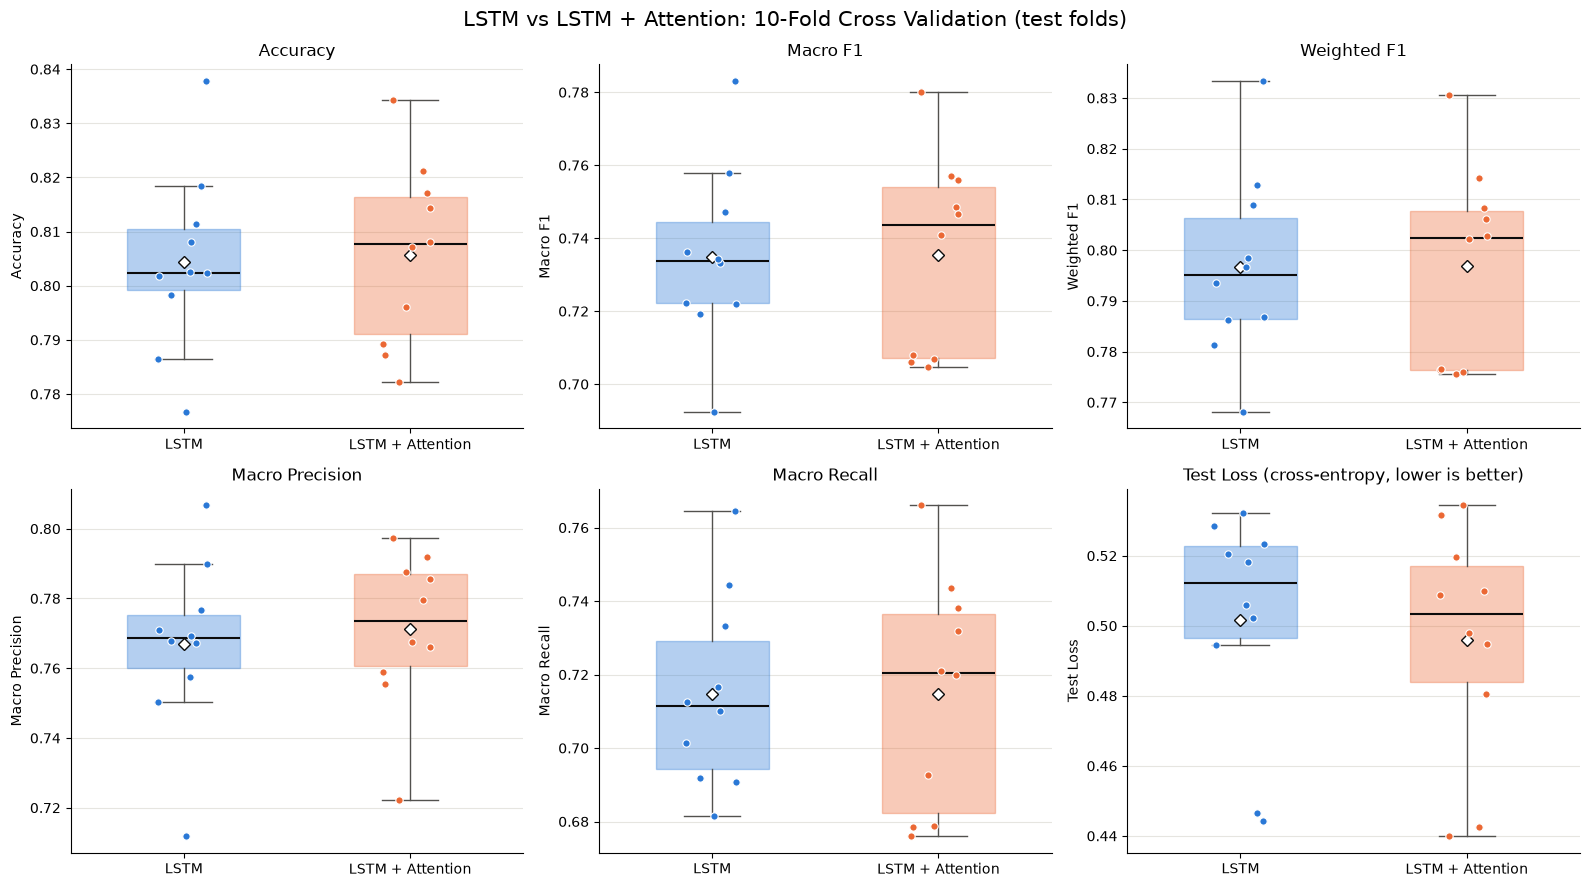

In [11]:
def compare_boxplot(ax, metric, title, ylabel=None):
    names = list(results)
    data = [results[n][metric].values for n in names]
    bp = ax.boxplot(
        data, widths=0.5, patch_artist=True, showmeans=True,
        medianprops=dict(color="#0b0b0b", linewidth=1.5),
        meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="#0b0b0b", markersize=6),
        whiskerprops=dict(color="#52514e"), capprops=dict(color="#52514e"),
        showfliers=False,   # every fold is already drawn as a dot below
    )
    ax.set_xticks(range(1, len(names) + 1), names)
    for patch, n in zip(bp["boxes"], names):
        patch.set_facecolor(MODEL_COLORS[n])
        patch.set_alpha(0.35)
        patch.set_edgecolor(MODEL_COLORS[n])
    rng = np.random.default_rng(0)
    for i, (n, d) in enumerate(zip(names, data), start=1):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=28, color=MODEL_COLORS[n],
                   edgecolor="white", linewidth=0.8, zorder=3)
    ax.set_title(title)
    ax.set_ylabel(ylabel or title)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


perf_metrics = [
    ("accuracy", "Accuracy"),
    ("f1_macro", "Macro F1"),
    ("f1_weighted", "Weighted F1"),
    ("precision_macro", "Macro Precision"),
    ("recall_macro", "Macro Recall"),
    ("test_loss", "Test Loss (cross-entropy, lower is better)"),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (metric, title) in zip(axes.ravel(), perf_metrics):
    compare_boxplot(ax, metric, title, ylabel=title.split(" (")[0])
fig.suptitle(f"LSTM vs LSTM + Attention: {n_folds}-Fold Cross Validation (test folds)", fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "boxplot_overall_metrics.png"), dpi=150, bbox_inches="tight")
plt.show()

### Per-class F1 Score

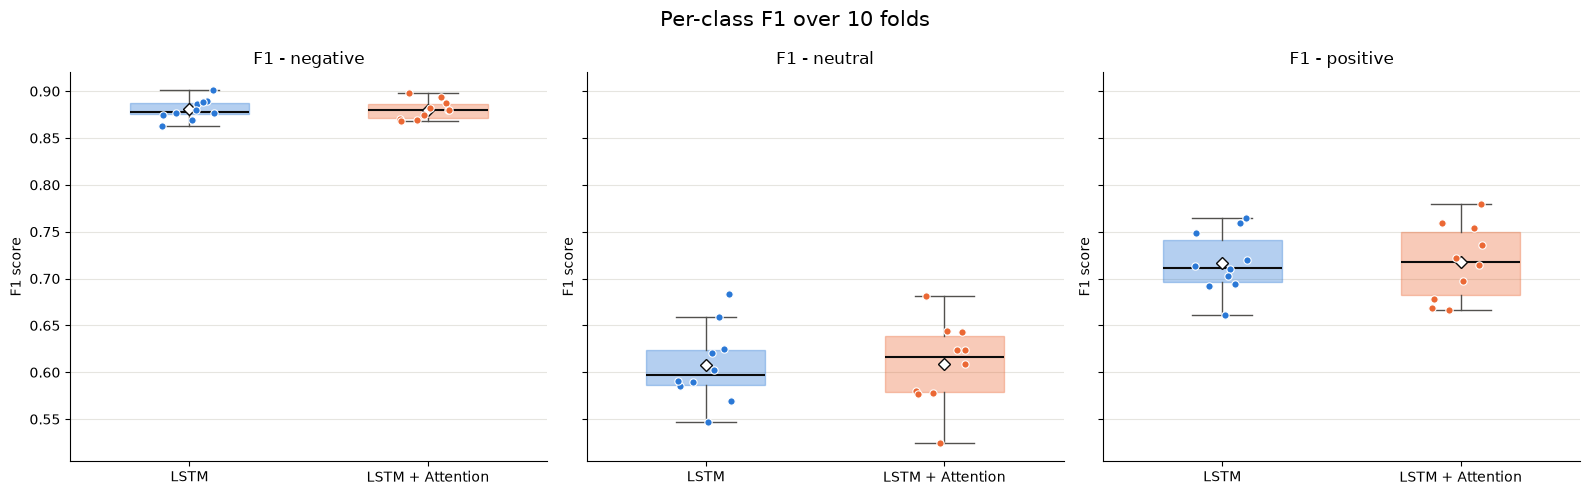

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, c in zip(axes, class_names):
    compare_boxplot(ax, f"f1_{c}", f"F1 - {c}", ylabel="F1 score")
fig.suptitle(f"Per-class F1 over {n_folds} folds", fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "boxplot_per_class_f1.png"), dpi=150, bbox_inches="tight")
plt.show()

### Training Cost

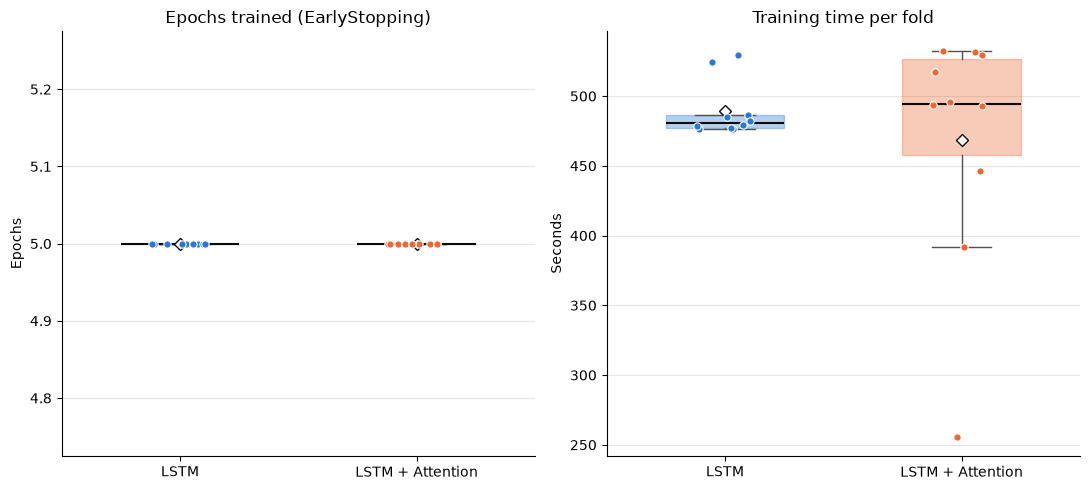

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
compare_boxplot(axes[0], "epochs_trained", "Epochs trained (EarlyStopping)", ylabel="Epochs")
compare_boxplot(axes[1], "train_time_s", "Training time per fold", ylabel="Seconds")
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "boxplot_training_cost.png"), dpi=150, bbox_inches="tight")
plt.show()

## Fold-by-Fold Comparison

Since both models are trained on the same folds, the scores are paired. The left plot joins the two scores of the same fold; the right plot shows the difference (Attention − LSTM) per fold. Bars above 0 mean attention was better on that fold.

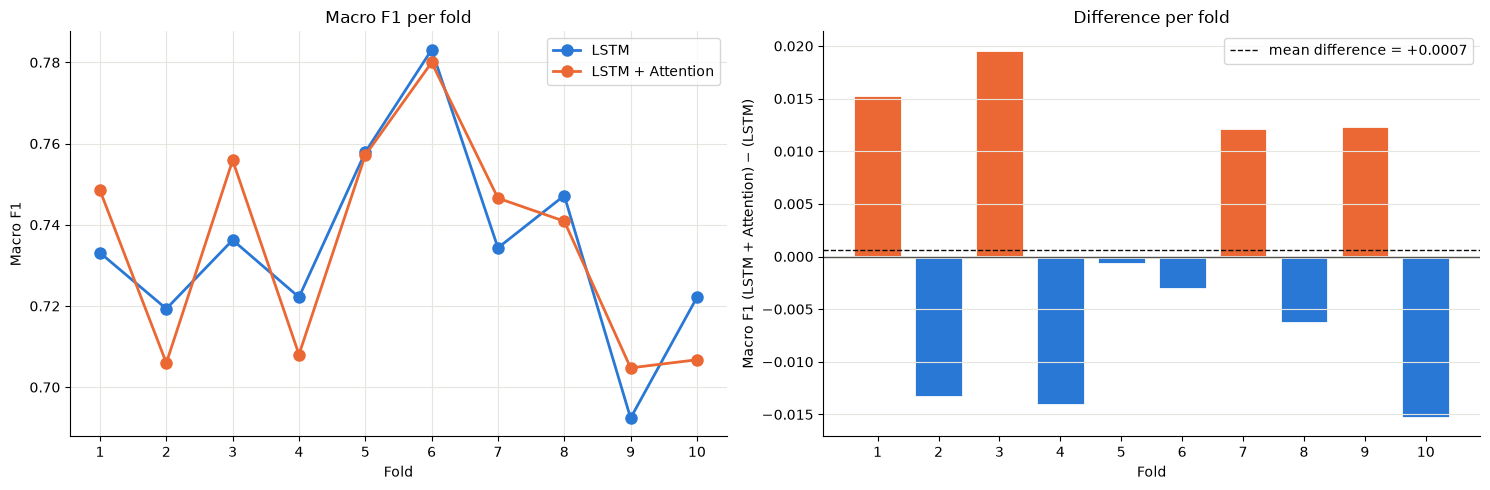

In [14]:
names = list(results)
a, b = names
fold_ids = results[a]["fold"].values

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for n in names:
    axes[0].plot(fold_ids, results[n]["f1_macro"], marker="o", linewidth=2, markersize=8,
                 color=MODEL_COLORS[n], label=n)
axes[0].set_xticks(fold_ids)
axes[0].set_xlabel("Fold"); axes[0].set_ylabel("Macro F1")
axes[0].set_title("Macro F1 per fold"); axes[0].legend()
axes[0].grid(color="#e6e5e0", linewidth=0.8)

diff = results[b]["f1_macro"].values - results[a]["f1_macro"].values
axes[1].bar(fold_ids, diff, color=[MODEL_COLORS[b] if d > 0 else MODEL_COLORS[a] for d in diff],
            edgecolor="white", linewidth=2)
axes[1].axhline(0, color="#52514e", linewidth=1)
axes[1].axhline(diff.mean(), color="#0b0b0b", linestyle="--", linewidth=1,
                label=f"mean difference = {diff.mean():+.4f}")
axes[1].set_xticks(fold_ids)
axes[1].set_xlabel("Fold"); axes[1].set_ylabel(f"Macro F1 ({b}) − ({a})")
axes[1].set_title("Difference per fold"); axes[1].legend()
axes[1].grid(axis="y", color="#e6e5e0", linewidth=0.8)
for ax in axes:
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "fold_by_fold_macro_f1.png"), dpi=150, bbox_inches="tight")
plt.show()

## Statistical Significance

Paired tests over the 10 folds (same folds for both models):

* **Paired t-test** – assumes the fold differences are roughly normal.
* **Wilcoxon signed-rank test** – non-parametric, does not assume normality.

p < 0.05 means the difference between the two models is unlikely to be due to chance in how the folds were trained.

In [15]:
rows = []
for metric, title in perf_metrics + [(f"f1_{c}", f"F1 - {c}") for c in class_names]:
    va, vb = results[a][metric].values, results[b][metric].values
    d = vb - va
    t_p = stats.ttest_rel(vb, va).pvalue
    try:
        w_p = stats.wilcoxon(vb, va).pvalue
    except ValueError:          # all differences are zero
        w_p = np.nan
    better = (d < 0).sum() if metric == "test_loss" else (d > 0).sum()
    rows.append({
        "metric": title.split(" (")[0],
        f"{a} mean": va.mean(),
        f"{b} mean": vb.mean(),
        "mean diff (Attn − LSTM)": d.mean(),
        "folds where Attention better": f"{better}/{n_folds}",
        "paired t-test p": t_p,
        "Wilcoxon p": w_p,
        "significant (p<0.05)": "yes" if t_p < 0.05 and (np.isnan(w_p) or w_p < 0.05) else "no",
    })
significance = pd.DataFrame(rows).set_index("metric")
significance.to_csv(os.path.join(output_dir, "cv_significance.csv"))
significance.round(4)

,LSTM mean,LSTM + Attention mean,mean diff (Attn − LSTM),folds where Attention better,paired t-test p,Wilcoxon p,significant (p<0.05)
metric,,,,,,,
Accuracy,0.8044,0.8057,0.0013,6/10,0.5656,0.6445,no
Macro F1,0.7348,0.7354,0.0007,4/10,0.8783,1.0000,no
Weighted F1,0.7966,0.7969,0.0002,5/10,0.9313,1.0000,no
Macro Precision,0.7668,0.7712,0.0044,7/10,0.1980,0.2324,no
Macro Recall,0.7147,0.7146,-0.0001,5/10,0.9902,0.9219,no
Test Loss,0.5017,0.4960,-0.0057,8/10,0.0474,0.0371,yes
F1 - negative,0.8806,0.8803,-0.0003,5/10,0.8373,0.8457,no
F1 - neutral,0.6073,0.6084,0.0011,4/10,0.8933,1.0000,no
F1 - positive,0.7164,0.7176,0.0012,6/10,0.8642,0.8457,no


## Pooled Confusion Matrices (out-of-fold predictions)

Every tweet is in the test fold exactly once, so joining the 10 test folds gives one prediction per tweet for the whole dataset.
Rows are normalised, so the diagonal is the recall of each class.

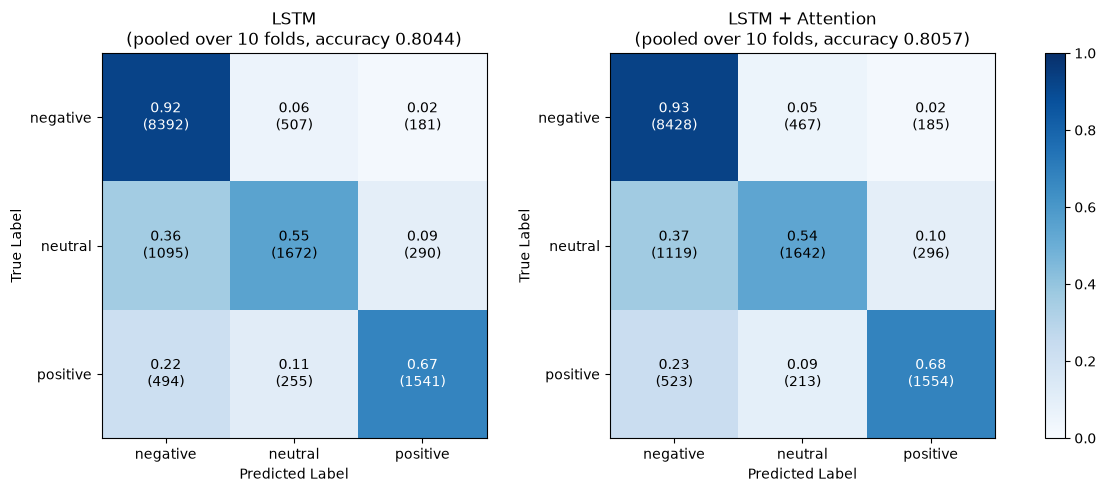

========== LSTM (pooled out-of-fold) ==========
              precision    recall  f1-score   support

    negative     0.8408    0.9242    0.8805      9080
     neutral     0.6869    0.5469    0.6090      3057
    positive     0.7659    0.6729    0.7164      2290

    accuracy                         0.8044     14427
   macro avg     0.7645    0.7147    0.7353     14427
weighted avg     0.7963    0.8044    0.7970     14427

========== LSTM + Attention (pooled out-of-fold) ==========
              precision    recall  f1-score   support

    negative     0.8369    0.9282    0.8802      9080
     neutral     0.7071    0.5371    0.6105      3057
    positive     0.7636    0.6786    0.7186      2290

    accuracy                         0.8057     14427
   macro avg     0.7692    0.7146    0.7364     14427
weighted avg     0.7978    0.8057    0.7974     14427



In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, n in zip(axes, names):
    pred = oof_probs[n].argmax(axis=1)
    cm = confusion_matrix(y_int, pred, labels=[0, 1, 2])
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{n}\n(pooled over {n_folds} folds, accuracy {accuracy_score(y_int, pred):.4f})")
    ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label")
    ax.set_xticks(range(3), class_names); ax.set_yticks(range(3), class_names)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm_norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.6 else "black")
fig.colorbar(im, ax=axes, fraction=0.025)
fig.savefig(os.path.join(output_dir, "confusion_matrices_pooled.png"), dpi=150, bbox_inches="tight")
plt.show()

for n in names:
    print(f"========== {n} (pooled out-of-fold) ==========")
    print(classification_report(y_int, oof_probs[n].argmax(axis=1), target_names=class_names, digits=4))

## Validation Loss Curves for Every Fold

Thin lines are the 10 folds and the thick line is the mean over the folds that were still training at that epoch.

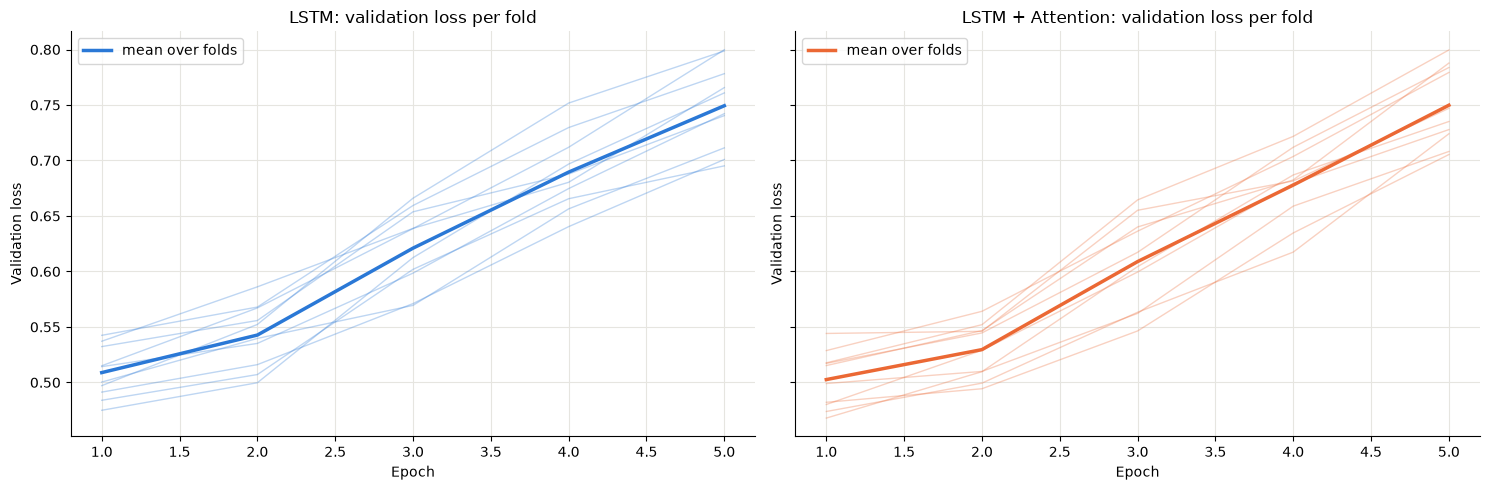

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, n in zip(axes, names):
    curves = [h["val_loss"] for h in histories[n]]
    for cv in curves:
        ax.plot(range(1, len(cv) + 1), cv, color=MODEL_COLORS[n], alpha=0.3, linewidth=1)
    longest = max(len(cv) for cv in curves)
    mean_curve = [np.mean([cv[e] for cv in curves if len(cv) > e]) for e in range(longest)]
    ax.plot(range(1, longest + 1), mean_curve, color=MODEL_COLORS[n], linewidth=2.5, label="mean over folds")
    ax.set_title(f"{n}: validation loss per fold")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Validation loss")
    ax.legend(); ax.grid(color="#e6e5e0", linewidth=0.8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "val_loss_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

In [18]:
r_a, r_b = results[a], results[b]
print(f"{'Metric':<18}{a:>22}{b:>22}")
for metric, title in perf_metrics:
    print(f"{title.split(' (')[0]:<18}"
          f"{r_a[metric].mean():>14.4f} ± {r_a[metric].std():.4f}"
          f"{r_b[metric].mean():>14.4f} ± {r_b[metric].std():.4f}")
print(f"{'Parameters':<18}{int(r_a['n_params'][0]):>22,}{int(r_b['n_params'][0]):>22,}")
print(f"{'Train time / fold':<18}{r_a['train_time_s'].mean():>21.0f}s{r_b['train_time_s'].mean():>21.0f}s")
print()

d = r_b["f1_macro"].mean() - r_a["f1_macro"].mean()
sig = significance.loc["Macro F1", "significant (p<0.05)"] == "yes"
winner = b if d > 0 else a
if sig:
    print(f"{winner} is significantly better on macro F1 ({d:+.4f}, p < 0.05 on both paired tests).")
else:
    print(f"Mean macro F1 difference is {d:+.4f} ({winner} slightly ahead), but it is NOT statistically "
          f"significant over the {n_folds} folds: the two models perform about the same on this dataset.")

Metric                              LSTM      LSTM + Attention
Accuracy                  0.8044 ± 0.0167        0.8057 ± 0.0167
Macro F1                  0.7348 ± 0.0245        0.7354 ± 0.0270
Weighted F1               0.7966 ± 0.0184        0.7969 ± 0.0195
Macro Precision           0.7668 ± 0.0250        0.7712 ± 0.0223
Macro Recall              0.7147 ± 0.0261        0.7146 ± 0.0316
Test Loss                 0.5017 ± 0.0319        0.4960 ± 0.0331
Parameters                     1,379,203             1,387,523
Train time / fold                   490s                  469s

Mean macro F1 difference is +0.0007 (LSTM + Attention slightly ahead), but it is NOT statistically significant over the 10 folds: the two models perform about the same on this dataset.


---
## Helpers for the Hold-out Test and Scatter Plots

In [19]:
# ---------- hold-out helpers ----------
holdout_size = 0.20


def run_holdout(tag, fn):
    # fn() trains one final model and returns (row dict, prediction array); cached like the CV runs
    row_path = os.path.join(output_dir, f"holdout_{tag}.json")
    pred_path = os.path.join(output_dir, f"holdout_pred_{tag}.npy")
    if not RERUN and os.path.exists(row_path) and os.path.exists(pred_path):
        print(f"{tag}: loading cached hold-out result")
        with open(row_path) as f:
            return json.load(f), np.load(pred_path)
    row, pred = fn()
    row = {k: (float(v) if isinstance(v, (np.floating, np.integer, float, int)) else v) for k, v in row.items()}
    with open(row_path, "w") as f:
        json.dump(row, f, indent=1)
    np.save(pred_path, pred)
    print(f"{tag}: hold-out done in {row.get('train_time_s', 0):.0f}s")
    return row, pred


def paired_scatter(ax, res_a, res_b, metric, name_a, name_b, color, lower_is_better=False):
    # one dot per fold: x = model A, y = model B. Above the diagonal = B scored higher on that fold
    xa, yb = res_a[metric].values, res_b[metric].values
    lo, hi = min(xa.min(), yb.min()), max(xa.max(), yb.max())
    pad = (hi - lo) * 0.08 or 0.01
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color="#8a8984", linestyle="--", linewidth=1)
    ax.scatter(xa, yb, s=60, color=color, edgecolor="white", linewidth=1, zorder=3)
    for k, (x_, y_) in enumerate(zip(xa, yb), start=1):
        ax.annotate(str(k), (x_, y_), xytext=(5, 4), textcoords="offset points", fontsize=8, color="#52514e")
    b_wins = (yb < xa).sum() if lower_is_better else (yb > xa).sum()
    ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(lo - pad, hi + pad); ax.set_aspect("equal")
    ax.set_xlabel(f"{name_a}"); ax.set_ylabel(f"{name_b}")
    ax.set_title(f"{metric}: {name_b} better on {b_wins}/{len(xa)} folds")
    ax.grid(color="#e6e5e0", linewidth=0.8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def cv_vs_holdout(ax, res_dict, hold_dict, colors, metric, title):
    # dots = the 10 CV test folds, star = the single hold-out score
    names_ = list(res_dict)
    rng = np.random.default_rng(1)
    for i, n in enumerate(names_):
        v = res_dict[n][metric].values
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=26, color=colors[n], alpha=0.55,
                   edgecolor="white", linewidth=0.6, label="CV folds" if i == 0 else None)
        ax.scatter([i], [v.mean()], marker="D", s=40, facecolor="white", edgecolor="#0b0b0b", zorder=3,
                   label="CV mean" if i == 0 else None)
        ax.scatter([i + 0.28], [hold_dict[n][metric]], marker="*", s=220, color=colors[n], edgecolor="#0b0b0b",
                   linewidth=0.8, zorder=4, label="hold-out" if i == 0 else None)
    ax.set_xticks(range(len(names_)), names_)
    ax.set_title(title); ax.set_ylabel(metric)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

## Exp 3: Fold-by-Fold Scatter (LSTM vs LSTM + Attention)

Each dot is one test fold: x = the LSTM score, y = the LSTM + Attention score on the same fold. Dots above the dashed diagonal are folds where attention scored higher (for test loss, below the diagonal is better). The two models track each other closely: a hard fold is hard for both.

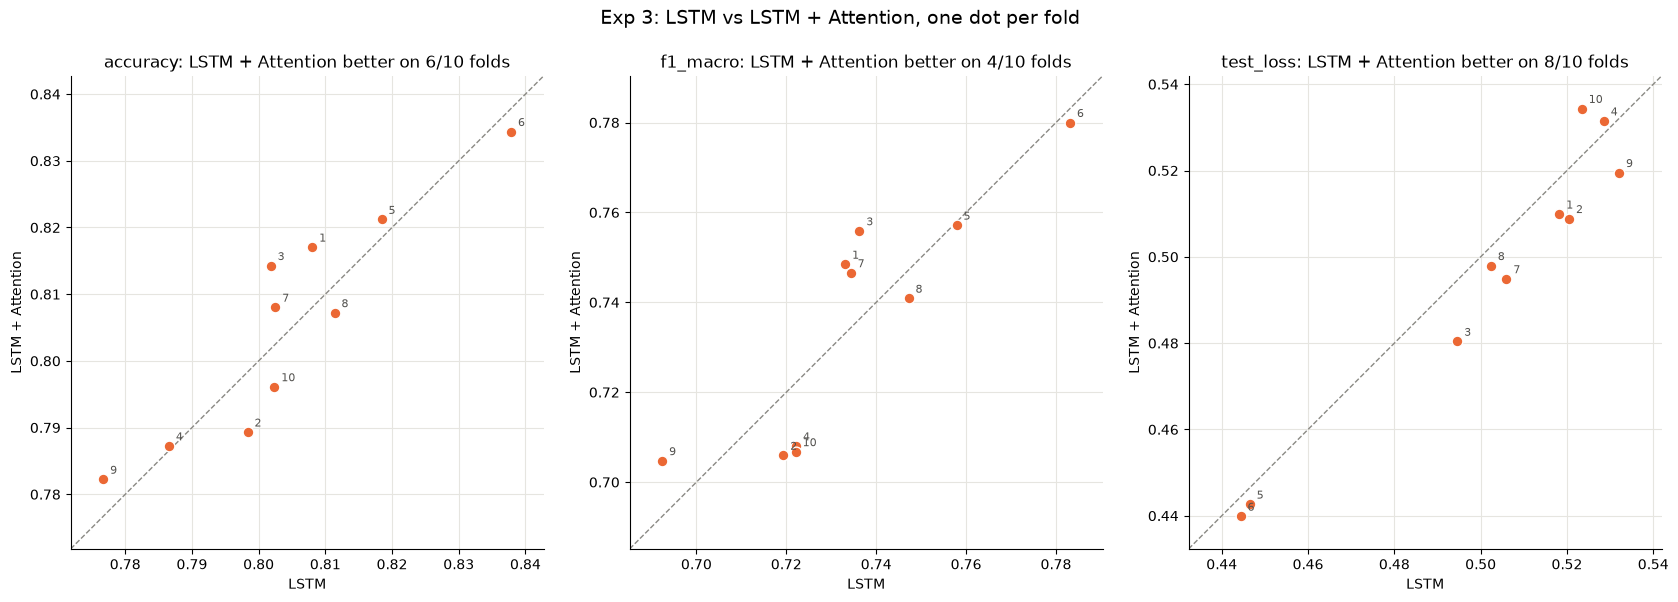

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8))
for ax, (metric, lib) in zip(axes, [("accuracy", False), ("f1_macro", False), ("test_loss", True)]):
    paired_scatter(ax, results[a], results[b], metric, a, b, MODEL_COLORS[b], lower_is_better=lib)
fig.suptitle(f"Exp 3: {a} vs {b}, one dot per fold", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(os.path.join(output_dir, "scatter_exp3_fold_by_fold.png"), dpi=150, bbox_inches="tight")
plt.show()

## Exp 3: Hold-out Test (80:20)

Both models are trained once on 80% of the tweets (stratified; 10% of it is the validation set for EarlyStopping, tokenizer fit on the training part only) and tested on the 20% hold-out tweets, with the same settings as in CV.

In [21]:
tw_train_idx, tw_hold_idx = train_test_split(np.arange(len(y_int)), test_size=holdout_size,
                                             random_state=seed, stratify=y_int)
print(f"Tweets: train {len(tw_train_idx)}, hold-out {len(tw_hold_idx)}")


def tweet_holdout(name):
    def fn():
        row, prob, _ = run_fold(MODELS[name], 99, tw_train_idx, tw_hold_idx)
        return row, prob
    return fn


tweet_hold, tweet_hold_prob = {}, {}
for name in MODELS:
    tweet_hold[name], tweet_hold_prob[name] = run_holdout(f"tweets_{MODEL_FILES[name]}", tweet_holdout(name))

hold_cols = ["accuracy", "f1_macro", "f1_weighted", "precision_macro", "recall_macro",
             "f1_negative", "f1_neutral", "f1_positive", "test_loss", "epochs_trained", "train_time_s"]
tweet_hold_table = pd.DataFrame({
    **{f"{n} (CV mean ± std)": results[n][hold_cols].mean().round(4).astype(str) + " ± " + results[n][hold_cols].std().round(4).astype(str) for n in MODELS},
    **{f"{n} (hold-out)": pd.Series({k: tweet_hold[n][k] for k in hold_cols}).round(4) for n in MODELS},
})
tweet_hold_table.to_csv(os.path.join(output_dir, "holdout_summary_tweets.csv"))
tweet_hold_table

Tweets: train 11541, hold-out 2886


tweets_lstm: hold-out done in 201s


tweets_lstm_attention: hold-out done in 269s


,LSTM (CV mean ± std),LSTM + Attention (CV mean ± std),LSTM (hold-out),LSTM + Attention (hold-out)
accuracy,0.8044 ± 0.0167,0.8057 ± 0.0167,0.7970,0.7983
f1_macro,0.7348 ± 0.0245,0.7354 ± 0.027,0.7163,0.7177
f1_weighted,0.7966 ± 0.0184,0.7969 ± 0.0195,0.7836,0.7861
precision_macro,0.7668 ± 0.025,0.7712 ± 0.0223,0.7656,0.7612
recall_macro,0.7147 ± 0.0261,0.7146 ± 0.0316,0.6905,0.6942
f1_negative,0.8806 ± 0.0112,0.8803 ± 0.0104,0.8763,0.8792
f1_neutral,0.6073 ± 0.0409,0.6084 ± 0.0449,0.5672,0.5751
f1_positive,0.7164 ± 0.0327,0.7176 ± 0.0399,0.7053,0.6989
test_loss,0.5017 ± 0.0319,0.496 ± 0.0331,0.5077,0.4967
epochs_trained,5.0 ± 0.0,5.0 ± 0.0,5.0000,5.0000


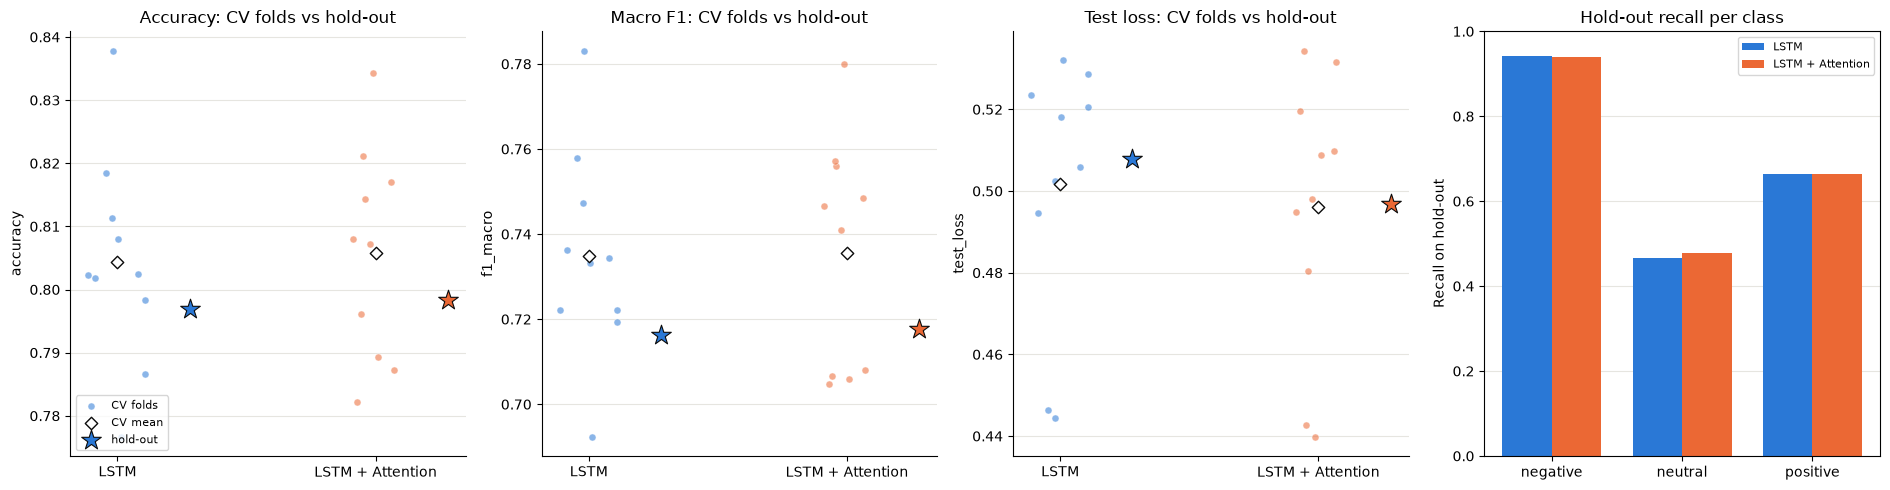

========== LSTM (hold-out, 2886 tweets) ==========
              precision    recall  f1-score   support

    negative     0.8191    0.9422    0.8763      1816
     neutral     0.7252    0.4657    0.5672       612
    positive     0.7525    0.6638    0.7053       458

    accuracy                         0.7970      2886
   macro avg     0.7656    0.6905    0.7163      2886
weighted avg     0.7886    0.7970    0.7836      2886

========== LSTM + Attention (hold-out, 2886 tweets) ==========
              precision    recall  f1-score   support

    negative     0.8258    0.9400    0.8792      1816
     neutral     0.7199    0.4788    0.5751       612
    positive     0.7379    0.6638    0.6989       458

    accuracy                         0.7983      2886
   macro avg     0.7612    0.6942    0.7177      2886
weighted avg     0.7894    0.7983    0.7861      2886



In [22]:
fig, axes = plt.subplots(1, 4, figsize=(19, 5))
for ax, (metric, title) in zip(axes[:3], [("accuracy", "Accuracy"), ("f1_macro", "Macro F1"), ("test_loss", "Test loss")]):
    cv_vs_holdout(ax, results, tweet_hold, MODEL_COLORS, metric, f"{title}: CV folds vs hold-out")
axes[0].legend(fontsize=8, loc="lower left")

ax = axes[3]
for i, n in enumerate(MODELS):
    pred = tweet_hold_prob[n].argmax(1)
    cm = confusion_matrix(y_int[tw_hold_idx], pred, labels=[0, 1, 2])
    recall = cm.diagonal() / cm.sum(1)
    ax.bar(np.arange(3) + (i - 0.5) * 0.38, recall, width=0.38, color=MODEL_COLORS[n], label=n)
ax.set_xticks(range(3), class_names); ax.set_ylim(0, 1); ax.set_ylabel("Recall on hold-out")
ax.set_title("Hold-out recall per class"); ax.legend(fontsize=8)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8); ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "holdout_exp3.png"), dpi=150, bbox_inches="tight")
plt.show()

for n in MODELS:
    print(f"========== {n} (hold-out, {len(tw_hold_idx)} tweets) ==========")
    print(classification_report(y_int[tw_hold_idx], tweet_hold_prob[n].argmax(1), target_names=class_names, digits=4))

---
# Part 2: Hold-out Test and Experiment 1 / Experiment 2 Models

**What this part adds**

* **Hold-out test for every experiment.** Cross validation gives 10 scores per model. In addition, each model is trained **once more** on 80% of the data and scored on the remaining **20% hold-out** set. It is the classic "final exam" on data the final model has never seen. Tweets and MNIST use a stratified random 80:20 split (seed 42). ETTh1 uses the **last 20% in time** as hold-out (the same test period as the original Exp 2 split). No hyperparameters are tuned on the CV results, so the hold-out stays an independent check. The final model never sees the hold-out rows, even though the separate CV runs also tested on them.
* **Scatter plots.** Fold-by-fold scatter plots of two models (each dot = one fold, the diagonal = a tie), CV-vs-hold-out plots, predicted-vs-actual scatter plots for the ETTh1 forecasts, and scatter plots of the ETTh1 data itself.
* **Experiment 1 (MNIST)** and **Experiment 2 (ETTh1)** models with 10-fold CV, box plots, significance tests and hold-out results.

| Exp | Model | Source notebook |
|---|---|---|
| 1 | **MLP**: Flatten(784) → Dense(128, relu) → Dense(64, relu) → Dense(10) | `exp1/exp_1.ipynb` |
| 1 | **CNN**: Conv(32, 3×3) → MaxPool → Conv(64, 3×3) → MaxPool → Flatten → Dense(128, relu) → Dense(10) | `exp1/exp_1.ipynb` |
| 2 | 10 LSTM forecasting models (see Part 3) | `exp2/LSTM.ipynb`, `exp2/lstm_ett_*.py` |

The Exp 1 models are rebuilt in Keras with the same layers as the PyTorch originals. The original Exp 1 training (lr 1e-5, batch 10, 100 epochs) would take days for 2 × 10 folds on CPU, so CV uses **Adam lr 1e-3, batch 128, ≤20 epochs, EarlyStopping (patience 3) on a 10% inner validation split**.

## Shared Helpers (CV runner + box plot for any number of models)

In [23]:
def run_cv_generic(tag, fold_fn, folds_, n_rows, n_classes, display_name):
    # Runs fold_fn on every fold, caches results to output/ (same caching rule as above: RERUN)
    csv_path = os.path.join(output_dir, f"cv_results_{tag}.csv")
    oof_path = os.path.join(output_dir, f"oof_probs_{tag}.npy")
    hist_path = os.path.join(output_dir, f"cv_history_{tag}.json")
    if not RERUN and all(os.path.exists(p) for p in (csv_path, oof_path, hist_path)):
        print(f"{display_name}: loading cached results from {output_dir}/")
        with open(hist_path) as f:
            return pd.read_csv(csv_path), np.load(oof_path), json.load(f)

    rows, hists = [], []
    oof = np.zeros((n_rows, n_classes), dtype="float32")
    for fold, (train_idx, test_idx) in enumerate(folds_):
        row, prob, hist = fold_fn(fold, train_idx, test_idx)
        oof[test_idx] = prob
        rows.append(row); hists.append(hist)
        print(f"{display_name} | fold {fold + 1:2d}/{len(folds_)} | acc {row['accuracy']:.4f} | "
              f"macro F1 {row['f1_macro']:.4f} | epochs {row['epochs_trained']:2d} | {row['train_time_s']:.0f}s")
    res = pd.DataFrame(rows)
    res.to_csv(csv_path, index=False)
    np.save(oof_path, oof)
    with open(hist_path, "w") as f:
        json.dump(hists, f)
    return res, oof, hists


def score_fold(fold, true, prob, history, train_time, model, class_labels):
    pred = prob.argmax(axis=1)
    labels_idx = list(range(len(class_labels)))
    row = {
        "fold": fold + 1,
        "accuracy": accuracy_score(true, pred),
        "f1_macro": f1_score(true, pred, average='macro'),
        "f1_weighted": f1_score(true, pred, average='weighted'),
        "precision_macro": precision_score(true, pred, average='macro', zero_division=0),
        "recall_macro": recall_score(true, pred, average='macro'),
        "test_loss": log_loss(true, prob, labels=labels_idx),
        "epochs_trained": len(history.history['loss']),
        "best_epoch": int(np.argmin(history.history['val_loss'])) + 1,
        "train_time_s": train_time,
        "n_params": model.count_params(),
    }
    for c, f1 in zip(class_labels, f1_score(true, pred, average=None, labels=labels_idx)):
        row[f"f1_{c}"] = f1
    hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
    return row, hist


def multi_boxplot(ax, res_dict, colors, metric, title, ylabel=None):
    # Same style as compare_boxplot above, but for any set of models
    names_ = list(res_dict)
    data = [res_dict[n][metric].values for n in names_]
    bp = ax.boxplot(
        data, widths=0.5, patch_artist=True, showmeans=True,
        medianprops=dict(color="#0b0b0b", linewidth=1.5),
        meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="#0b0b0b", markersize=6),
        whiskerprops=dict(color="#52514e"), capprops=dict(color="#52514e"),
        showfliers=False,
    )
    ax.set_xticks(range(1, len(names_) + 1), names_, rotation=15 if len(names_) > 2 else 0,
                  ha="right" if len(names_) > 2 else "center")
    for patch, n in zip(bp["boxes"], names_):
        patch.set_facecolor(colors[n]); patch.set_alpha(0.35); patch.set_edgecolor(colors[n])
    rng = np.random.default_rng(0)
    for i, (n, d) in enumerate(zip(names_, data), start=1):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=28, color=colors[n],
                   edgecolor="white", linewidth=0.8, zorder=3)
    ax.set_title(title)
    ax.set_ylabel(ylabel or title)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def summary_table(res_dict, cols):
    t = pd.DataFrame({
        n: r[cols].mean().round(4).astype(str) + " ± " + r[cols].std().round(4).astype(str)
        for n, r in res_dict.items()
    })
    t.loc["parameters"] = [f"{int(r['n_params'].iloc[0]):,}" for r in res_dict.values()]
    return t


def paired_tests(res_dict, baseline, metrics):
    # Every model vs the baseline, paired over the same folds
    rows_ = []
    for n in res_dict:
        if n == baseline:
            continue
        for metric, title in metrics:
            va, vb = res_dict[baseline][metric].values, res_dict[n][metric].values
            d = vb - va
            t_p = stats.ttest_rel(vb, va).pvalue
            try:
                w_p = stats.wilcoxon(vb, va).pvalue
            except ValueError:
                w_p = np.nan
            better = (d < 0).sum() if metric == "test_loss" else (d > 0).sum()
            rows_.append({
                "model": n, "metric": title.split(" (")[0],
                f"{baseline} mean": va.mean(), "model mean": vb.mean(),
                f"mean diff (model − {baseline})": d.mean(),
                f"folds where model better": f"{better}/{len(va)}",
                "paired t-test p": t_p, "Wilcoxon p": w_p,
                "significant (p<0.05)": "yes" if t_p < 0.05 and (np.isnan(w_p) or w_p < 0.05) else "no",
            })
    return pd.DataFrame(rows_).set_index(["model", "metric"])

## Exp 1: MLP vs CNN on MNIST (10-Fold CV)

As in Exp 1, the MNIST train and test sets are joined (70,000 images) and scaled to [0, 1]. The data is split into 10 stratified folds; each fold is the test set once, and 10% of the other 9 folds is the validation set for EarlyStopping. Both models get the same folds and the same seed per fold, so the scores are paired.

In [24]:
from tensorflow.keras.layers import Flatten, Conv2D, MaxPooling2D

(mx_tr, my_tr), (mx_te, my_te) = tf.keras.datasets.mnist.load_data()
X_mnist = (np.concatenate([mx_tr, mx_te]).astype("float32") / 255.0)[..., np.newaxis]   # (70000, 28, 28, 1)
y_mnist = np.concatenate([my_tr, my_te]).astype("int64")
digit_names = [str(d) for d in range(10)]
print("MNIST:", X_mnist.shape, y_mnist.shape)

# CV training setup for Exp 1 (see the note at the top of Part 2)
mnist_lr = 1e-3
mnist_batch = 128
mnist_epochs = 20
mnist_patience = 3


def build_mlp():
    # Linear(784,128) -> ReLU -> Linear(128,64) -> ReLU -> Linear(64,10)
    m = Sequential([
        Input(shape=(28, 28, 1)),
        Flatten(),
        Dense(128, activation="relu"),
        Dense(64, activation="relu"),
        Dense(10, activation="softmax"),
    ], name="MLP")
    m.compile(optimizer=tf.keras.optimizers.Adam(mnist_lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


def build_cnn():
    # Conv(1->32,3,pad1)-ReLU-MaxPool2 -> Conv(32->64,3,pad1)-ReLU-MaxPool2 -> Flatten -> Linear(3136,128)-ReLU -> Linear(128,10)
    m = Sequential([
        Input(shape=(28, 28, 1)),
        Conv2D(32, 3, padding="same", activation="relu"),
        MaxPooling2D(2),
        Conv2D(64, 3, padding="same", activation="relu"),
        MaxPooling2D(2),
        Flatten(),
        Dense(128, activation="relu"),
        Dense(10, activation="softmax"),
    ], name="CNN")
    m.compile(optimizer=tf.keras.optimizers.Adam(mnist_lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


EXP1_MODELS = {"MLP": build_mlp, "CNN": build_cnn}
EXP1_FILES = {"MLP": "exp1_mlp", "CNN": "exp1_cnn"}
EXP1_COLORS = {"MLP": "#d97706", "CNN": "#0e7490"}

for n, b in EXP1_MODELS.items():
    print(f"{n}: {b().count_params():,} parameters")   # same counts as the PyTorch models (109,386 / 421,642)

mnist_folds = list(StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed).split(X_mnist, y_mnist))


def make_exp1_fold_fn(build_fn):
    def fold_fn(fold, train_idx, test_idx):
        tr_idx, val_idx = train_test_split(train_idx, test_size=inner_val_size,
                                           random_state=seed + fold, stratify=y_mnist[train_idx])
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed + fold)
        model = build_fn()
        es = EarlyStopping(monitor="val_loss", patience=mnist_patience, restore_best_weights=True)
        start = time.time()
        history = model.fit(X_mnist[tr_idx], y_mnist[tr_idx], epochs=mnist_epochs, batch_size=mnist_batch,
                            validation_data=(X_mnist[val_idx], y_mnist[val_idx]), callbacks=[es], verbose=0)
        train_time = time.time() - start
        prob = model.predict(X_mnist[test_idx], batch_size=1024, verbose=0)
        row, hist = score_fold(fold, y_mnist[test_idx], prob, history, train_time, model, digit_names)
        return row, prob, hist
    return fold_fn

MNIST: (70000, 28, 28, 1) (70000,)
MLP: 109,386 parameters
CNN: 421,642 parameters


In [25]:
mnist_results, mnist_oof, mnist_hist = {}, {}, {}
for n, b in EXP1_MODELS.items():
    mnist_results[n], mnist_oof[n], mnist_hist[n] = run_cv_generic(
        EXP1_FILES[n], make_exp1_fold_fn(b), mnist_folds, len(y_mnist), 10, n)
    print()

mnist_cols = ["accuracy", "f1_macro", "f1_weighted", "precision_macro", "recall_macro",
              "test_loss", "epochs_trained", "train_time_s"]
mnist_summary = summary_table(mnist_results, mnist_cols)
mnist_summary.to_csv(os.path.join(output_dir, "cv_summary_exp1_mnist.csv"))
mnist_summary

MLP: loading cached results from output/

CNN: loading cached results from output/



,MLP,CNN
accuracy,0.9721 ± 0.0039,0.9885 ± 0.002
f1_macro,0.9719 ± 0.0039,0.9884 ± 0.002
f1_weighted,0.9721 ± 0.0039,0.9885 ± 0.002
precision_macro,0.9721 ± 0.0037,0.9885 ± 0.002
recall_macro,0.9719 ± 0.0039,0.9884 ± 0.002
test_loss,0.094 ± 0.0097,0.0378 ± 0.0059
epochs_trained,9.1 ± 1.4491,7.9 ± 2.2336
train_time_s,15.6459 ± 2.3432,240.5388 ± 68.936
parameters,"109,386","421,642"


### Box Plots: MLP vs CNN (10-Fold CV, test folds)

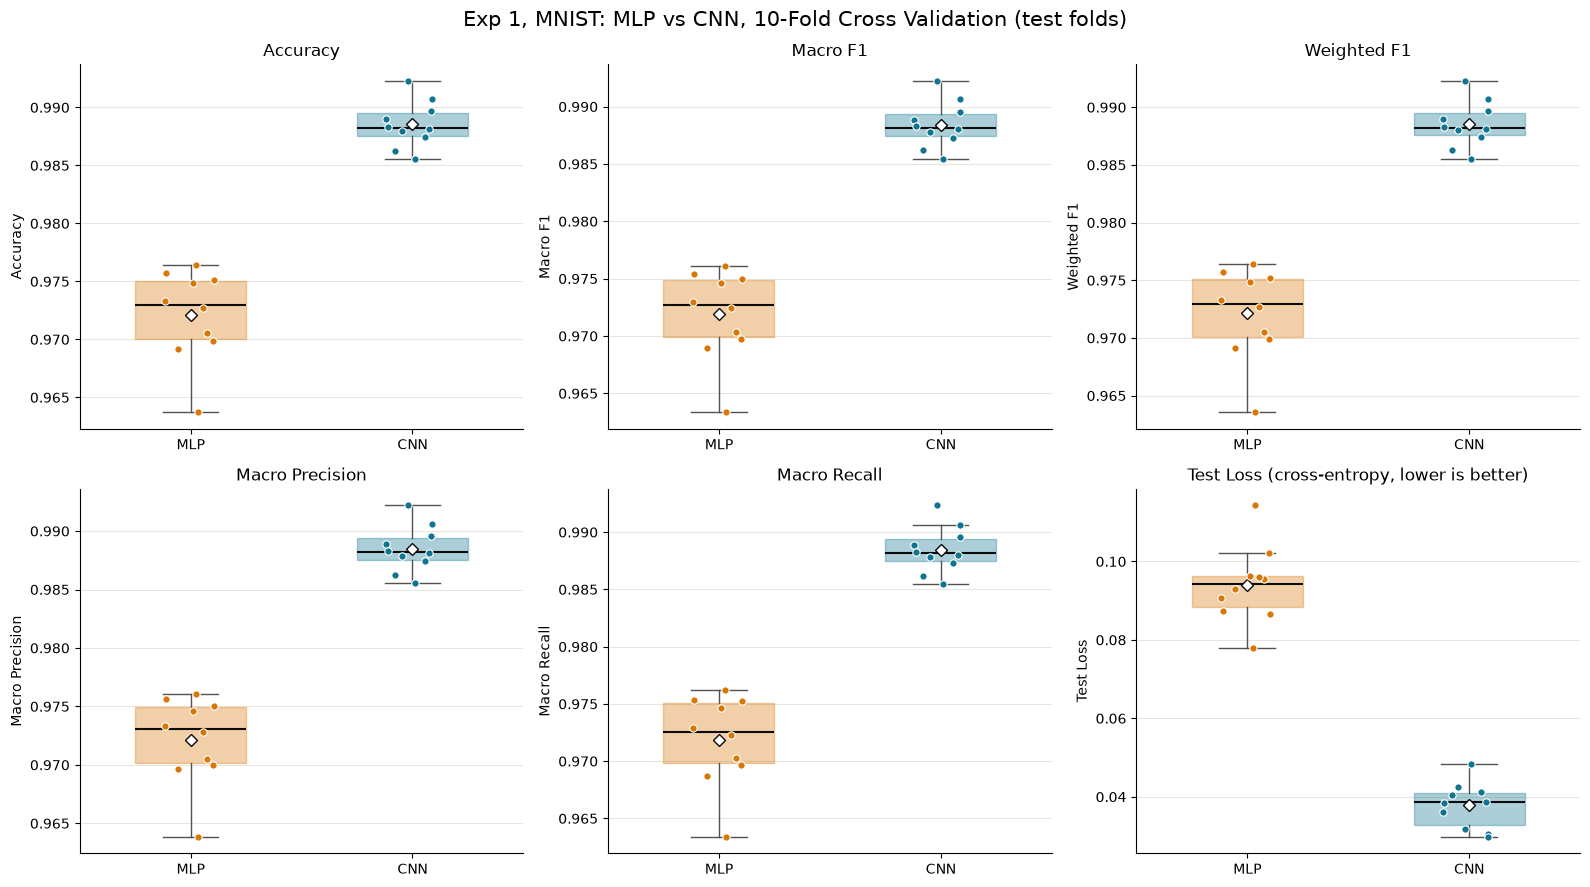

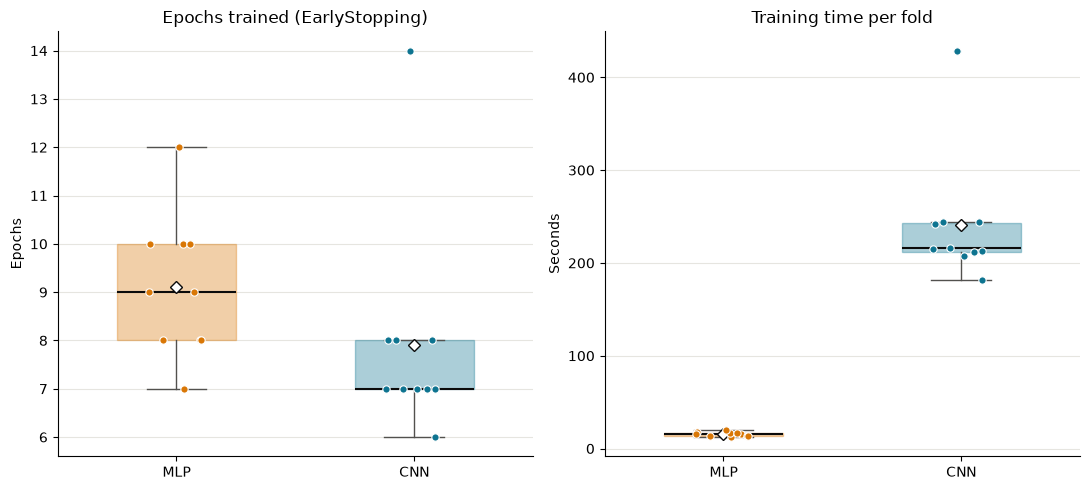

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (metric, title) in zip(axes.ravel(), perf_metrics):
    multi_boxplot(ax, mnist_results, EXP1_COLORS, metric, title, ylabel=title.split(" (")[0])
fig.suptitle(f"Exp 1, MNIST: MLP vs CNN, {n_folds}-Fold Cross Validation (test folds)", fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "boxplot_exp1_mnist.png"), dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
multi_boxplot(axes[0], mnist_results, EXP1_COLORS, "epochs_trained", "Epochs trained (EarlyStopping)", ylabel="Epochs")
multi_boxplot(axes[1], mnist_results, EXP1_COLORS, "train_time_s", "Training time per fold", ylabel="Seconds")
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "boxplot_exp1_training_cost.png"), dpi=150, bbox_inches="tight")
plt.show()

### Per-digit F1 (10-Fold CV)

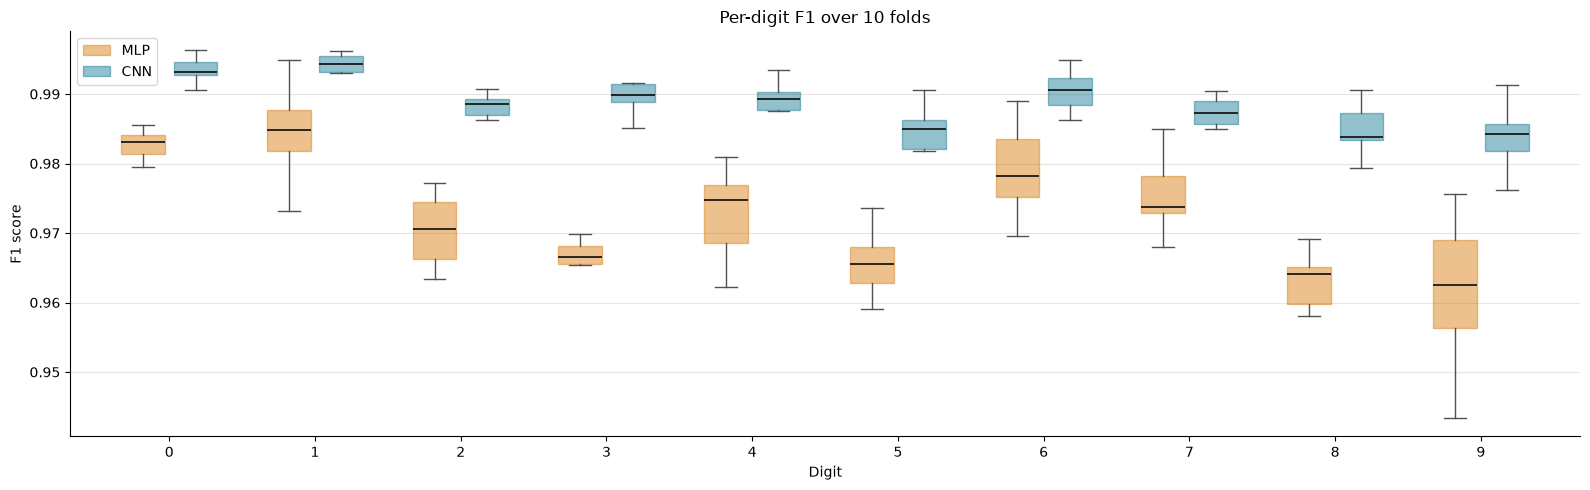

In [27]:
fig, ax = plt.subplots(figsize=(16, 5))
pos = np.arange(10)
for k, (n, off) in enumerate(zip(mnist_results, (-0.18, 0.18))):
    data = [mnist_results[n][f"f1_{d}"].values for d in digit_names]
    bp = ax.boxplot(data, positions=pos + off, widths=0.3, patch_artist=True, showfliers=False,
                    medianprops=dict(color="#0b0b0b", linewidth=1.2),
                    whiskerprops=dict(color="#52514e"), capprops=dict(color="#52514e"))
    for patch in bp["boxes"]:
        patch.set_facecolor(EXP1_COLORS[n]); patch.set_alpha(0.45); patch.set_edgecolor(EXP1_COLORS[n])
    bp["boxes"][0].set_label(n)
ax.set_xticks(pos, digit_names); ax.set_xlabel("Digit"); ax.set_ylabel("F1 score")
ax.set_title(f"Per-digit F1 over {n_folds} folds")
ax.legend(); ax.grid(axis="y", color="#e6e5e0", linewidth=0.8); ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "boxplot_exp1_per_digit_f1.png"), dpi=150, bbox_inches="tight")
plt.show()

### Statistical Significance (CNN vs MLP, paired over 10 folds)

In [28]:
mnist_sig = paired_tests(mnist_results, "MLP", perf_metrics)
mnist_sig.to_csv(os.path.join(output_dir, "cv_significance_exp1_mnist.csv"))
mnist_sig.round(6)

MLP mean  model mean  mean diff (model − MLP)  \
model metric                                                           
CNN   Accuracy         0.972143    0.988543                 0.016400   
      Macro F1         0.971901    0.988438                 0.016537   
      Weighted F1      0.972124    0.988540                 0.016416   
      Macro Precision  0.972149    0.988487                 0.016338   
      Macro Recall     0.971859    0.988450                 0.016591   
      Test Loss        0.094026    0.037785                -0.056240   

                      folds where model better  paired t-test p  Wilcoxon p  \
model metric                                                                  
CNN   Accuracy                           10/10              0.0    0.001953   
      Macro F1                           10/10              0.0    0.001953   
      Weighted F1                        10/10              0.0    0.001953   
      Macro Precision                    10/10              0.0    0.001953   
      Macro Recall                       10/10              0.0    0.001953   
      Test Loss                          10/10              0.0    0.001953   

                      significant (p<0.05)  
model metric                                
CNN   Accuracy                         yes  
      Macro F1                         yes  
      Weighted F1                      yes  
      Macro Precision                  yes  
      Macro Recall                     yes  
      Test Loss                        yes

### Pooled Confusion Matrices (out-of-fold, MNIST)

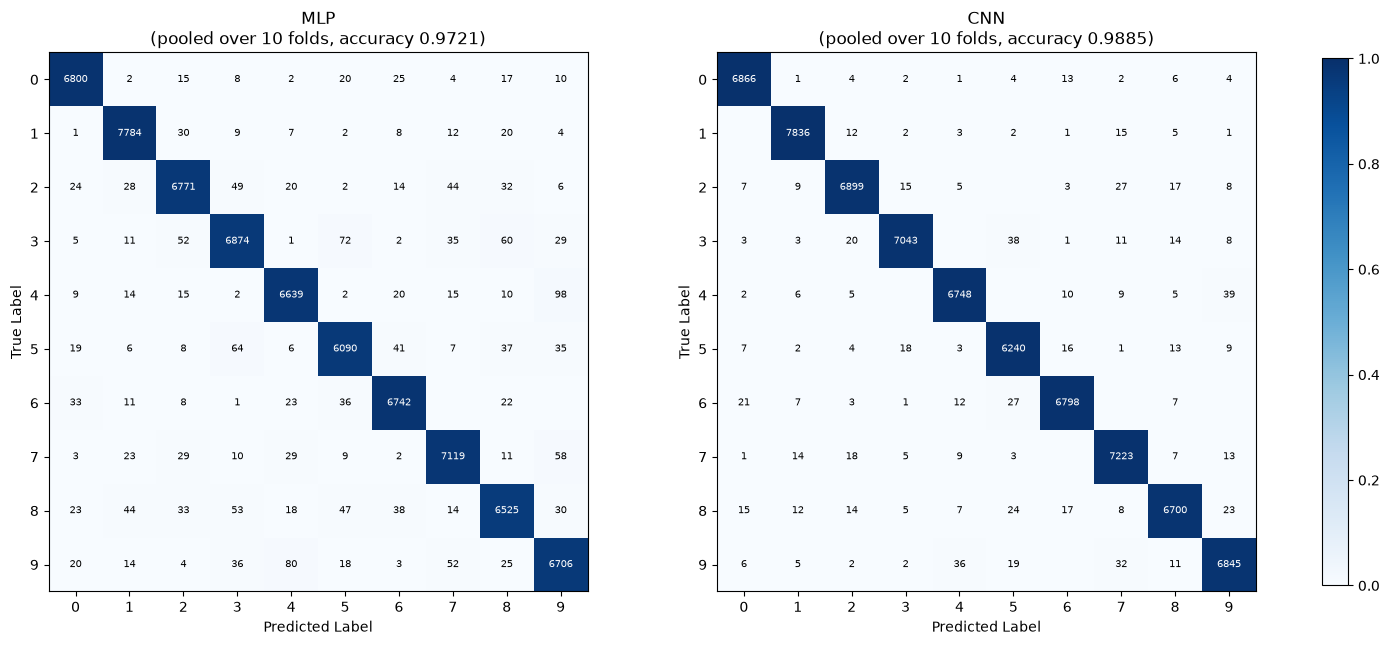

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, n in zip(axes, mnist_results):
    pred = mnist_oof[n].argmax(axis=1)
    cm = confusion_matrix(y_mnist, pred, labels=range(10))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{n}\n(pooled over {n_folds} folds, accuracy {accuracy_score(y_mnist, pred):.4f})")
    ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label")
    ax.set_xticks(range(10), digit_names); ax.set_yticks(range(10), digit_names)
    for i in range(10):
        for j in range(10):
            if cm[i, j]:
                ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7,
                        color="white" if cm_norm[i, j] > 0.6 else "black")
fig.colorbar(im, ax=axes, fraction=0.02)
fig.savefig(os.path.join(output_dir, "confusion_matrices_pooled_exp1_mnist.png"), dpi=150, bbox_inches="tight")
plt.show()

### Fold-by-Fold Scatter (MLP vs CNN)

Every dot is one fold. All dots above the diagonal mean the CNN won every fold (below the diagonal for test loss).

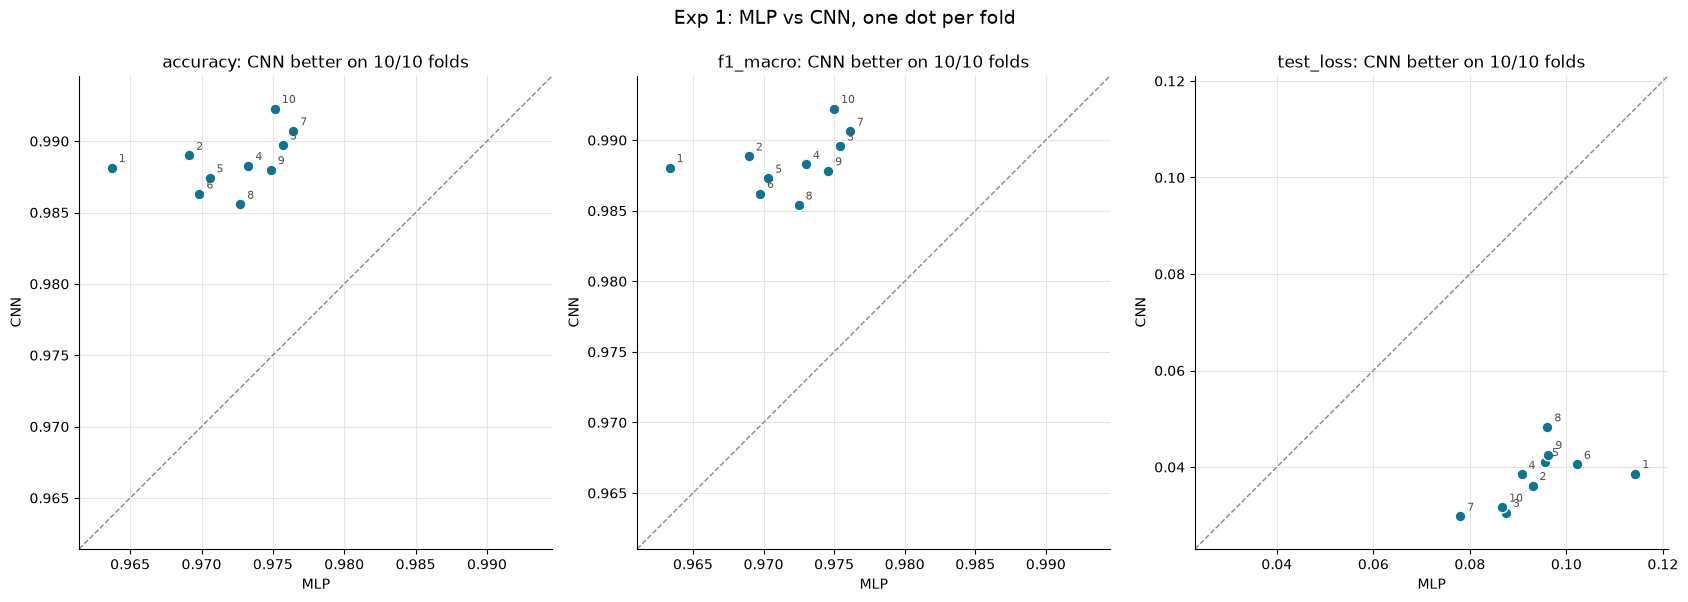

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8))
for ax, (metric, lib) in zip(axes, [("accuracy", False), ("f1_macro", False), ("test_loss", True)]):
    paired_scatter(ax, mnist_results["MLP"], mnist_results["CNN"], metric, "MLP", "CNN", EXP1_COLORS["CNN"], lower_is_better=lib)
fig.suptitle("Exp 1: MLP vs CNN, one dot per fold", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(os.path.join(output_dir, "scatter_exp1_fold_by_fold.png"), dpi=150, bbox_inches="tight")
plt.show()

### Hold-out Test (80:20, MNIST)

Each model is trained once on 80% of the 70,000 images (stratified; 10% of it for EarlyStopping) and tested on the 14,000 hold-out images.

In [31]:
mn_train_idx, mn_hold_idx = train_test_split(np.arange(len(y_mnist)), test_size=holdout_size,
                                             random_state=seed, stratify=y_mnist)
print(f"MNIST: train {len(mn_train_idx)}, hold-out {len(mn_hold_idx)}")

mnist_hold, mnist_hold_prob = {}, {}
for n, b in EXP1_MODELS.items():
    def fn(b=b):
        row, prob, _ = make_exp1_fold_fn(b)(99, mn_train_idx, mn_hold_idx)
        return row, prob
    mnist_hold[n], mnist_hold_prob[n] = run_holdout(EXP1_FILES[n], fn)

mcols_h = ["accuracy", "f1_macro", "f1_weighted", "precision_macro", "recall_macro", "test_loss", "epochs_trained", "train_time_s"]
mnist_hold_table = pd.DataFrame({
    **{f"{n} (CV mean ± std)": mnist_results[n][mcols_h].mean().round(4).astype(str) + " ± " + mnist_results[n][mcols_h].std().round(4).astype(str) for n in EXP1_MODELS},
    **{f"{n} (hold-out)": pd.Series({k: mnist_hold[n][k] for k in mcols_h}).round(4) for n in EXP1_MODELS},
})
mnist_hold_table.to_csv(os.path.join(output_dir, "holdout_summary_mnist.csv"))
mnist_hold_table

MNIST: train 56000, hold-out 14000


W0000 00:00:1795267679.203392  524146 cpu_allocator_impl.cc:82] Allocation of 158054400 exceeds 10% of free system memory.


exp1_mlp: hold-out done in 17s


W0000 00:00:1795267697.125718  524146 cpu_allocator_impl.cc:82] Allocation of 158054400 exceeds 10% of free system memory.


exp1_cnn: hold-out done in 246s


,MLP (CV mean ± std),CNN (CV mean ± std),MLP (hold-out),CNN (hold-out)
accuracy,0.9721 ± 0.0039,0.9885 ± 0.002,0.9722,0.9885
f1_macro,0.9719 ± 0.0039,0.9884 ± 0.002,0.9720,0.9885
f1_weighted,0.9721 ± 0.0039,0.9885 ± 0.002,0.9722,0.9885
precision_macro,0.9721 ± 0.0037,0.9885 ± 0.002,0.9723,0.9885
recall_macro,0.9719 ± 0.0039,0.9884 ± 0.002,0.9719,0.9885
test_loss,0.094 ± 0.0097,0.0378 ± 0.0059,0.0935,0.0378
epochs_trained,9.1 ± 1.4491,7.9 ± 2.2336,9.0000,9.0000
train_time_s,15.6459 ± 2.3432,240.5388 ± 68.936,17.2715,246.3213


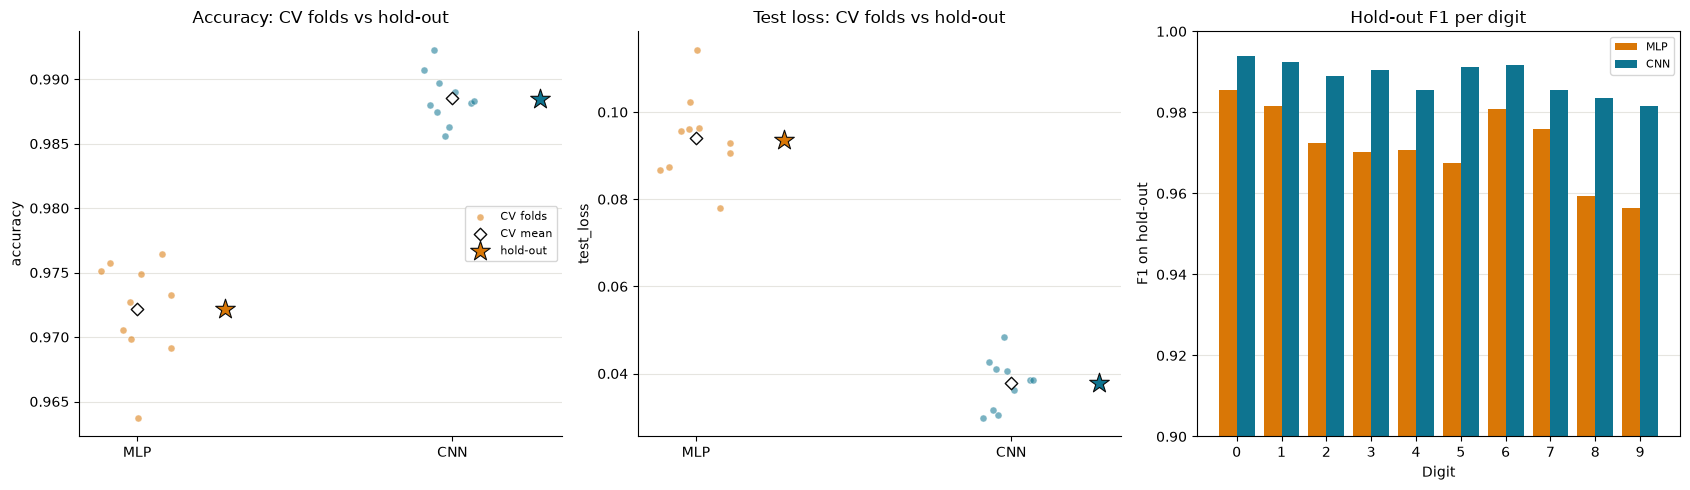

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (metric, title) in zip(axes[:2], [("accuracy", "Accuracy"), ("test_loss", "Test loss")]):
    cv_vs_holdout(ax, mnist_results, mnist_hold, EXP1_COLORS, metric, f"{title}: CV folds vs hold-out")
axes[0].legend(fontsize=8, loc="center right")
ax = axes[2]
for n, off in zip(EXP1_MODELS, (-0.2, 0.2)):
    f1s = f1_score(y_mnist[mn_hold_idx], mnist_hold_prob[n].argmax(1), average=None)
    ax.bar(np.arange(10) + off, f1s, width=0.4, color=EXP1_COLORS[n], label=n)
ax.set_xticks(range(10), digit_names); ax.set_ylim(0.9, 1.0); ax.set_xlabel("Digit"); ax.set_ylabel("F1 on hold-out")
ax.set_title("Hold-out F1 per digit"); ax.legend(fontsize=8)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8); ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "holdout_exp1.png"), dpi=150, bbox_inches="tight")
plt.show()

---
# Part 3: Experiment 2 Models, ETTh1 Oil Temperature Forecasting (10-Fold Time-Series CV)

Experiment 2 forecasts the transformer **oil temperature (OT)** for the next hour from past hours of the **ETTh1** dataset (Electricity Transformer Temperature, hourly, 17,420 rows, 2016-07-01 to 2018-06-26), the same dataset used in Exp 2 (`tarit21/electricity-transformer-dataset-etdataset`, `ETT-small/ETTh1.csv`).

| # | Model | Source | Input window | Input features |
|---|---|---|---|---|
| 1–6 | **LSTM: X + OT** (one model per load feature X) | `exp2/LSTM.ipynb` "Single Feature + past OT" | 48 h | X ∈ {HUFL, HULL, MUFL, MULL, LUFL, LULL} + past OT |
| 7 | **LSTM: 6 loads + OT** | `exp2/LSTM.ipynb` "All 6 Features + past OT" | 48 h | all 6 loads + past OT |
| 8 | **Hour-chain LSTM: 6 loads + OT** | `exp2/LSTM.ipynb` "dynamic LSTM based on hour" | 6 h | all 6 loads + past OT |
| 9 | **LSTM: HUFL only** | `exp2/lstm_ett_univariate.py` (submitted univariate version) | 48 h | HUFL |
| 10 | **Hour-chain LSTM: 6 loads** | `exp2/lstm_ett_multivariate.py` (submitted multivariate version) | 6 h | all 6 loads |

* **LSTM** = `LSTM(hidden 6, 1 layer)` on the window → last timestep → `Dense(1)`, as in Exp 2.
* **Hour-chain LSTM** = one single-step LSTM cell per past hour (6 cells, hidden 6). Cell *i* gets hour *i*'s features concatenated with cell *i−1*'s output and starts from a zero state; the last cell's output → `Dense(1)`, as in Exp 2.
* A **naive persistence baseline** (predict OT(t) = OT(t−1)) is added as a reference. It is not an Exp 2 model, but shows how much the LSTMs add over simply copying the last reading.

**Why time-series CV instead of shuffled 10-fold:** shuffling would put future hours in the training set and nearly-identical neighbouring hours on both sides of the split. The data is therefore split with **forward-chaining 10-fold CV** (`TimeSeriesSplit(n_splits=10)`): the series is cut into 11 consecutive blocks, and fold *k* trains on blocks 1…*k* and tests on block *k+1* (≈1,583 hours ≈ 66 days). The last 10% of each training part (in time order) is the validation set for EarlyStopping, and the MinMax scalers are fit on the training part only, as in Exp 2. Every model uses the same folds, so the scores are paired. Errors are reported in °C after inverse scaling.

**Training setup:** Exp 2 used Adam lr 0.0001, batch 5, 100 epochs. That is too slow for 10 models × 10 folds on CPU, so CV uses **Adam lr 0.001, batch 64, ≤100 epochs, EarlyStopping (val MSE, patience 10, best weights restored)**. The models are rebuilt in Keras with the same layers as the PyTorch originals.

In [33]:
import kagglehub
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.layers import Concatenate, Reshape

ett_path = kagglehub.dataset_download("tarit21/electricity-transformer-dataset-etdataset")
ett = pd.read_csv(os.path.join(ett_path, "ETT-small", "ETTh1.csv"))
print(ett.shape, ett["date"].iloc[0], "->", ett["date"].iloc[-1])

loads = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL"]
ett_target = "OT"

# Exp 2 settings
seq_length = 48          # window of the standard LSTM models
chain_hours = 6          # window of the hour-chain models (one LSTM cell per hour)
ett_hidden = 6

# CV training setup (see the note above)
ett_lr = 1e-3
ett_batch = 64
ett_epochs = 100
ett_patience = 10

EXP2_MODELS = {
    **{f"LSTM: {f} + OT": dict(tag=f"exp2_lstm_{f.lower()}_ot", kind="lstm", features=[f, "OT"]) for f in loads},
    "LSTM: 6 loads + OT": dict(tag="exp2_lstm_all_ot", kind="lstm", features=loads + ["OT"]),
    "Hour-chain LSTM: 6 loads + OT": dict(tag="exp2_chain_all_ot", kind="chain", features=loads + ["OT"]),
    "LSTM: HUFL only": dict(tag="exp2_lstm_hufl", kind="lstm", features=["HUFL"]),
    "Hour-chain LSTM: 6 loads": dict(tag="exp2_chain_all", kind="chain", features=loads),
}


def build_ett_lstm(n_feat):
    inp = Input(shape=(seq_length, n_feat))
    x = LSTM(ett_hidden)(inp)                 # output of the last timestep
    out = Dense(1)(x)
    m = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(ett_lr), loss="mse")
    return m


def build_ett_chain(n_feat):
    # cell i sees hour i (+ previous cell's output), each cell starts from a zero state
    inp = Input(shape=(chain_hours, n_feat))
    prev = None
    for i in range(chain_hours):
        x_i = inp[:, i, :]
        if prev is not None:
            x_i = Concatenate()([x_i, prev])
        x_i = Reshape((1, -1))(x_i)                          # one timestep
        prev = LSTM(ett_hidden, name=f"hour_cell_{i + 1}")(x_i)   # single step from zero state = LSTMCell
    out = Dense(1)(prev)
    m = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(ett_lr), loss="mse")
    return m


def make_windows(X, y, window):
    # same as create_sequences in Exp 2: hours i..i+window-1 -> OT at hour i+window
    idx = np.arange(len(X) - window)
    Xs = np.stack([X[i:i + window] for i in idx])
    return Xs.astype("float32"), y[idx + window].astype("float32")


for n, cfg in EXP2_MODELS.items():
    b = build_ett_lstm if cfg["kind"] == "lstm" else build_ett_chain
    print(f"{n:<32} {b(len(cfg['features'])).count_params():>4} parameters")

ett_folds = list(TimeSeriesSplit(n_splits=n_folds).split(ett))
for k, (tr, te) in enumerate(ett_folds):
    print(f"fold {k + 1:2d}: train rows 0-{tr[-1]:5d} ({len(tr):5d} h) | test rows {te[0]:5d}-{te[-1]:5d} "
          f"({ett['date'].iloc[te[0]][:10]} -> {ett['date'].iloc[te[-1]][:10]})")

(17420, 8) 2016-07-01 00:00:00 -> 2018-06-26 19:00:00
LSTM: HUFL + OT                   223 parameters
LSTM: HULL + OT                   223 parameters
LSTM: MUFL + OT                   223 parameters
LSTM: MULL + OT                   223 parameters
LSTM: LUFL + OT                   223 parameters
LSTM: LULL + OT                   223 parameters
LSTM: 6 loads + OT                343 parameters


Hour-chain LSTM: 6 loads + OT    2743 parameters
LSTM: HUFL only                   199 parameters
Hour-chain LSTM: 6 loads         2599 parameters
fold  1: train rows 0- 1589 ( 1590 h) | test rows  1590- 3172 (2016-09-05 -> 2016-11-10)
fold  2: train rows 0- 3172 ( 3173 h) | test rows  3173- 4755 (2016-11-10 -> 2017-01-15)
fold  3: train rows 0- 4755 ( 4756 h) | test rows  4756- 6338 (2017-01-15 -> 2017-03-22)
fold  4: train rows 0- 6338 ( 6339 h) | test rows  6339- 7921 (2017-03-22 -> 2017-05-27)
fold  5: train rows 0- 7921 ( 7922 h) | test rows  7922- 9504 (2017-05-27 -> 2017-08-01)
fold  6: train rows 0- 9504 ( 9505 h) | test rows  9505-11087 (2017-08-01 -> 2017-10-05)
fold  7: train rows 0-11087 (11088 h) | test rows 11088-12670 (2017-10-06 -> 2017-12-10)
fold  8: train rows 0-12670 (12671 h) | test rows 12671-14253 (2017-12-10 -> 2018-02-14)
fold  9: train rows 0-14253 (14254 h) | test rows 14254-15836 (2018-02-14 -> 2018-04-21)
fold 10: train rows 0-15836 (15837 h) | test rows 15

### ETTh1 Data Exploration

Plots of the raw ETTh1 data before any modelling: how OT moves over time, how each variable is distributed, how the load features relate to OT, and how strongly OT depends on its own previous hour. That last relationship is why past OT is such a strong input and why the naive baseline is hard to beat.

            HUFL       HULL       MUFL       MULL       LUFL       LULL  \
count  17420.000  17420.000  17420.000  17420.000  17420.000  17420.000   
mean       7.375      2.242      4.300      0.882      3.066      0.857   
std        7.068      2.042      6.827      1.809      1.165      0.600   
min      -22.706     -4.756    -25.088     -5.934     -1.188     -1.371   
25%        5.827      0.737      3.296     -0.284      2.315      0.670   
50%        8.774      2.210      5.970      0.959      2.833      0.975   
75%       11.788      3.684      8.635      2.203      3.625      1.218   
max       23.644     10.114     17.341      7.747      8.498      3.046   

              OT  
count  17420.000  
mean      13.325  
std        8.567  
min       -4.080  
25%        6.964  
50%       11.396  
75%       18.079  
max       46.007  


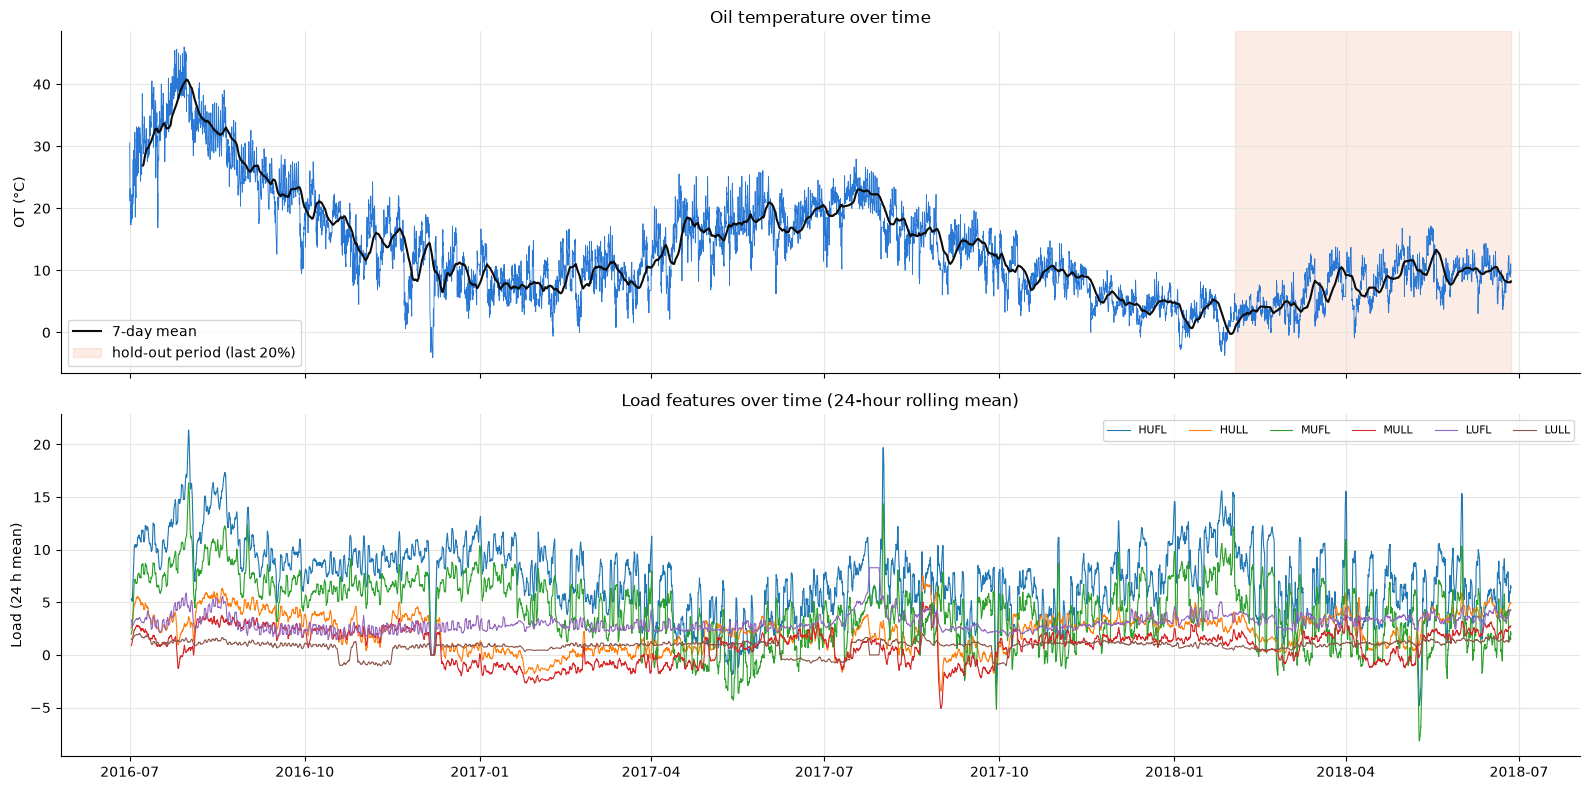

In [34]:
ett_dates = pd.to_datetime(ett["date"])
eda_cols = loads + ["OT"]
eda_names = {"HUFL": "High Useful Load", "HULL": "High Useless Load", "MUFL": "Middle Useful Load",
             "MULL": "Middle Useless Load", "LUFL": "Low Useful Load", "LULL": "Low Useless Load", "OT": "Oil Temperature"}
print(ett[eda_cols].describe().round(3))

# Line plot: OT over time, with the hold-out period shaded
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
axes[0].plot(ett_dates, ett["OT"], color="#2a78d6", linewidth=0.6)
axes[0].plot(ett_dates, ett["OT"].rolling(24 * 7).mean(), color="#0b0b0b", linewidth=1.5, label="7-day mean")
axes[0].axvspan(ett_dates.iloc[int(len(ett) * (1 - holdout_size))], ett_dates.iloc[-1], color="#eb6834", alpha=0.12,
                label="hold-out period (last 20%)")
axes[0].set_ylabel("OT (°C)"); axes[0].set_title("Oil temperature over time"); axes[0].legend()
for f in loads:
    axes[1].plot(ett_dates, ett[f].rolling(24).mean(), linewidth=0.8, label=f)
axes[1].set_ylabel("Load (24 h mean)"); axes[1].set_title("Load features over time (24-hour rolling mean)")
axes[1].legend(ncol=6, fontsize=8)
for ax in axes:
    ax.grid(color="#e6e5e0", linewidth=0.8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "eda_ett_line.png"), dpi=150, bbox_inches="tight")
plt.show()

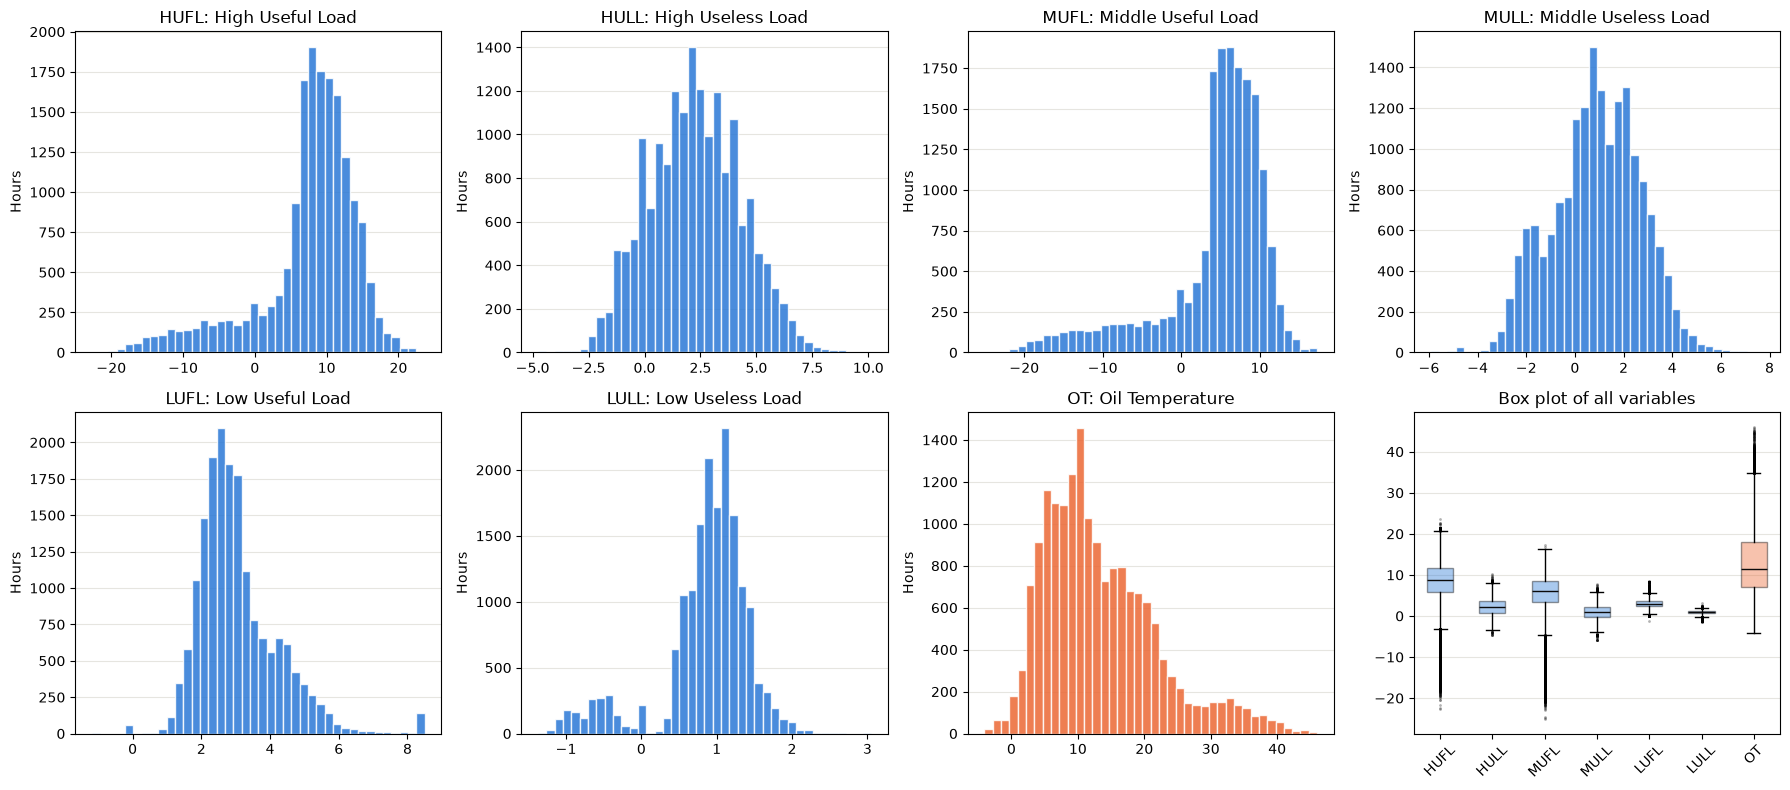

In [35]:
# Histograms and box plots of every variable
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), eda_cols):
    ax.hist(ett[c], bins=40, color="#2a78d6" if c != "OT" else "#eb6834", edgecolor="white", alpha=0.85)
    ax.set_title(f"{c}: {eda_names[c]}"); ax.set_ylabel("Hours")
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8); ax.set_axisbelow(True)
ax = axes.ravel()[-1]
bp = ax.boxplot([ett[c] for c in eda_cols], patch_artist=True, showfliers=True,
                flierprops=dict(marker=".", markersize=2, alpha=0.3), medianprops=dict(color="#0b0b0b"))
for patch, c in zip(bp["boxes"], eda_cols):
    patch.set_facecolor("#eb6834" if c == "OT" else "#2a78d6"); patch.set_alpha(0.4)
ax.set_xticks(range(1, len(eda_cols) + 1), eda_cols, rotation=45); ax.set_title("Box plot of all variables")
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "eda_ett_hist_box.png"), dpi=150, bbox_inches="tight")
plt.show()

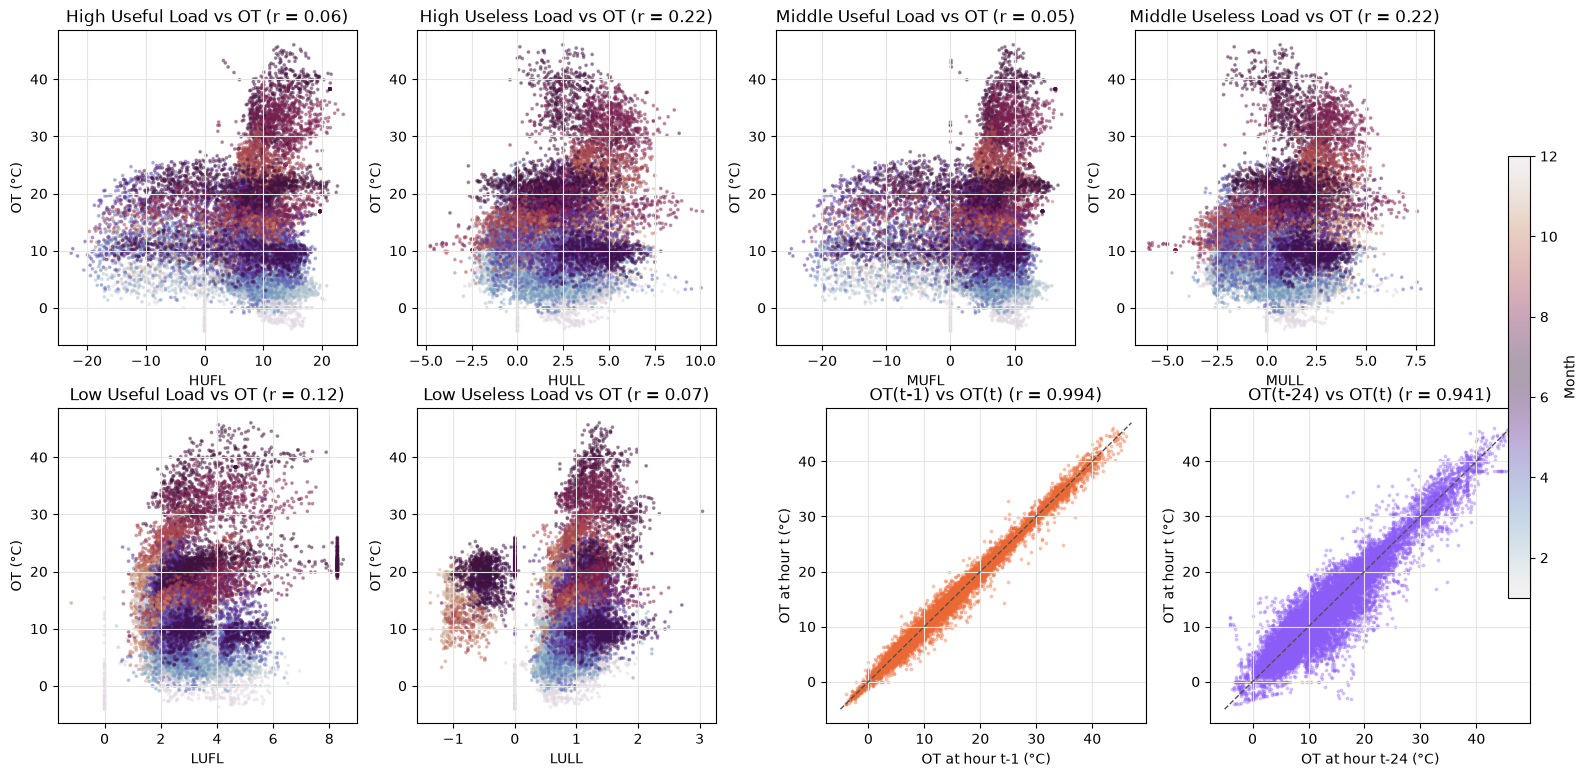

In [36]:
# Scatter plots: every load feature vs OT, coloured by month, plus OT(t-1) vs OT(t)
fig, axes = plt.subplots(2, 4, figsize=(19, 9))
month = ett_dates.dt.month.values
for ax, f in zip(axes.ravel()[:6], loads):
    sc = ax.scatter(ett[f], ett["OT"], c=month, cmap="twilight", s=3, alpha=0.4)
    r = np.corrcoef(ett[f], ett["OT"])[0, 1]
    ax.set_xlabel(f); ax.set_ylabel("OT (°C)"); ax.set_title(f"{eda_names[f]} vs OT (r = {r:.2f})")
    ax.grid(color="#e6e5e0", linewidth=0.8)
fig.colorbar(sc, ax=axes.ravel()[:6].tolist(), fraction=0.015, label="Month")
ax = axes.ravel()[6]
ax.scatter(ett["OT"].values[:-1], ett["OT"].values[1:], s=3, alpha=0.3, color="#eb6834")
r = np.corrcoef(ett["OT"].values[:-1], ett["OT"].values[1:])[0, 1]
ax.plot([-5, 47], [-5, 47], color="#52514e", linestyle="--", linewidth=1)
ax.set_xlabel("OT at hour t-1 (°C)"); ax.set_ylabel("OT at hour t (°C)"); ax.set_title(f"OT(t-1) vs OT(t) (r = {r:.3f})")
ax.grid(color="#e6e5e0", linewidth=0.8)
ax = axes.ravel()[7]
ax.scatter(ett["OT"].values[:-24], ett["OT"].values[24:], s=3, alpha=0.3, color="#8b5cf6")
r24 = np.corrcoef(ett["OT"].values[:-24], ett["OT"].values[24:])[0, 1]
ax.plot([-5, 47], [-5, 47], color="#52514e", linestyle="--", linewidth=1)
ax.set_xlabel("OT at hour t-24 (°C)"); ax.set_ylabel("OT at hour t (°C)"); ax.set_title(f"OT(t-24) vs OT(t) (r = {r24:.3f})")
ax.grid(color="#e6e5e0", linewidth=0.8)
fig.savefig(os.path.join(output_dir, "eda_ett_scatter.png"), dpi=150, bbox_inches="tight")
plt.show()

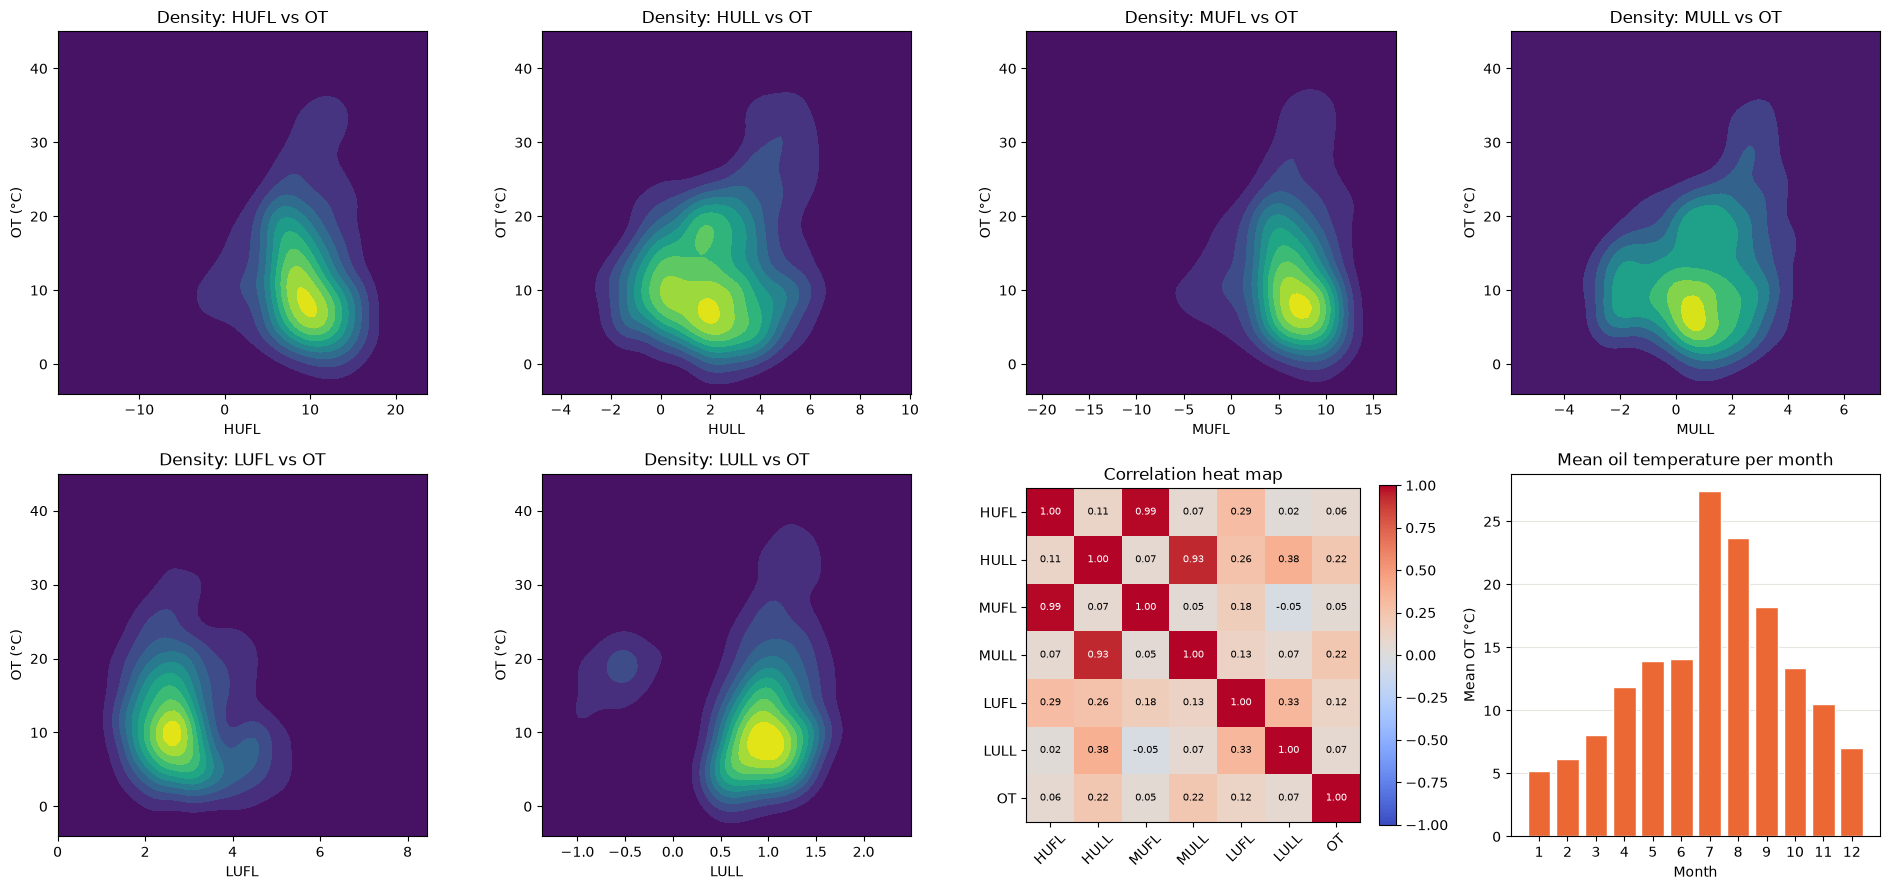

In [37]:
# Contour (2-D density) plots of each load vs OT, and the correlation heat map
from scipy.stats import gaussian_kde
samp = ett.sample(n=4000, random_state=seed)
fig, axes = plt.subplots(2, 4, figsize=(19, 9))
for ax, f in zip(axes.ravel()[:6], loads):
    x_, y_ = samp[f].values, samp["OT"].values
    kde = gaussian_kde(np.vstack([x_, y_]))
    gx, gy = np.meshgrid(np.linspace(x_.min(), x_.max(), 80), np.linspace(y_.min(), y_.max(), 80))
    gz = kde(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
    ax.contourf(gx, gy, gz, levels=10, cmap="viridis")
    ax.set_xlabel(f); ax.set_ylabel("OT (°C)"); ax.set_title(f"Density: {f} vs OT")
corr = ett[eda_cols].corr()
ax = axes.ravel()[6]
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(7), eda_cols, rotation=45); ax.set_yticks(range(7), eda_cols)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.set_title("Correlation heat map")
fig.colorbar(im, ax=ax, fraction=0.046)
ax = axes.ravel()[7]
monthly = ett.assign(m=ett_dates.dt.month).groupby("m")["OT"].mean()
ax.bar(monthly.index, monthly.values, color="#eb6834", edgecolor="white")
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month"); ax.set_ylabel("Mean OT (°C)"); ax.set_title("Mean oil temperature per month")
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8); ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "eda_ett_contour_corr.png"), dpi=150, bbox_inches="tight")
plt.show()

### Run the 10-fold time-series CV for all Exp 2 models

For each test fold we record MAE, RMSE and R² in °C (after inverse scaling), the scaled test MSE, epochs trained and training time. The out-of-fold predictions are saved so the predicted OT can be plotted over the whole tested period.

In [38]:
ett_values = ett[loads + ["OT"]]


def ett_fold(cfg, fold, train_idx, test_idx):
    feats = cfg["features"]
    window = seq_length if cfg["kind"] == "lstm" else chain_hours
    n_val = int(len(train_idx) * inner_val_size)
    tr_idx, val_idx = train_idx[:-n_val], train_idx[-n_val:]        # validation = most recent 10% of training

    f_scaler, t_scaler = MinMaxScaler(), MinMaxScaler()              # fit on training part only
    Xtr = f_scaler.fit_transform(ett_values.iloc[tr_idx][feats]); ytr = t_scaler.fit_transform(ett_values.iloc[tr_idx][[ett_target]])
    Xva = f_scaler.transform(ett_values.iloc[val_idx][feats]);    yva = t_scaler.transform(ett_values.iloc[val_idx][[ett_target]])
    Xte = f_scaler.transform(ett_values.iloc[test_idx][feats]);   yte = t_scaler.transform(ett_values.iloc[test_idx][[ett_target]])
    Xtr, ytr = make_windows(Xtr, ytr, window)
    Xva, yva = make_windows(Xva, yva, window)
    Xte, yte = make_windows(Xte, yte, window)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed + fold)
    model = (build_ett_lstm if cfg["kind"] == "lstm" else build_ett_chain)(len(feats))
    es = EarlyStopping(monitor="val_loss", patience=ett_patience, restore_best_weights=True)
    start = time.time()
    history = model.fit(Xtr, ytr, epochs=ett_epochs, batch_size=ett_batch, shuffle=True,
                        validation_data=(Xva, yva), callbacks=[es], verbose=0)
    train_time = time.time() - start

    pred_s = model.predict(Xte, batch_size=1024, verbose=0)
    pred = t_scaler.inverse_transform(pred_s).ravel()
    true = t_scaler.inverse_transform(yte).ravel()
    row = {
        "fold": fold + 1,
        "MAE": mean_absolute_error(true, pred),
        "RMSE": float(np.sqrt(mean_squared_error(true, pred))),
        "R2": r2_score(true, pred),
        "test_mse_scaled": mean_squared_error(yte, pred_s),
        "epochs_trained": len(history.history["loss"]),
        "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,
        "train_time_s": train_time,
        "n_params": model.count_params(),
    }
    hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
    pred_rows = test_idx[window:]                                    # rows of the series that were predicted
    return row, pred_rows, pred, hist


def run_ett_cv(name, cfg):
    tag = cfg["tag"]
    csv_path = os.path.join(output_dir, f"cv_results_{tag}.csv")
    oof_path = os.path.join(output_dir, f"oof_pred_{tag}.npy")
    hist_path = os.path.join(output_dir, f"cv_history_{tag}.json")
    if not RERUN and all(os.path.exists(p) for p in (csv_path, oof_path, hist_path)):
        print(f"{name}: loading cached results from {output_dir}/")
        with open(hist_path) as f:
            return pd.read_csv(csv_path), np.load(oof_path), json.load(f)

    rows, hists = [], []
    oof = np.full(len(ett), np.nan, dtype="float32")                 # NaN = row never predicted
    for fold, (train_idx, test_idx) in enumerate(ett_folds):
        row, pred_rows, pred, hist = ett_fold(cfg, fold, train_idx, test_idx)
        oof[pred_rows] = pred
        rows.append(row); hists.append(hist)
        print(f"{name} | fold {fold + 1:2d}/{n_folds} | MAE {row['MAE']:.4f} | RMSE {row['RMSE']:.4f} | "
              f"R2 {row['R2']:.4f} | epochs {row['epochs_trained']:3d} | {row['train_time_s']:.0f}s")
    res = pd.DataFrame(rows)
    res.to_csv(csv_path, index=False)
    np.save(oof_path, oof)
    with open(hist_path, "w") as f:
        json.dump(hists, f)
    return res, oof, hists


ett_results, ett_oof, ett_hist = {}, {}, {}
for name, cfg in EXP2_MODELS.items():
    ett_results[name], ett_oof[name], ett_hist[name] = run_ett_cv(name, cfg)
    print()

# Naive persistence reference: OT(t) = OT(t-1), scored on the same rows as the 48 h LSTMs
ot = ett["OT"].values
naive_rows = []
for fold, (train_idx, test_idx) in enumerate(ett_folds):
    rows_ = test_idx[seq_length:]
    true, pred = ot[rows_], ot[rows_ - 1]
    naive_rows.append({"fold": fold + 1, "MAE": mean_absolute_error(true, pred),
                       "RMSE": float(np.sqrt(mean_squared_error(true, pred))), "R2": r2_score(true, pred),
                       "epochs_trained": 0, "train_time_s": 0.0, "n_params": 0})
ett_results["Naive: last OT"] = pd.DataFrame(naive_rows)

LSTM: HUFL + OT: loading cached results from output/

LSTM: HULL + OT: loading cached results from output/

LSTM: MUFL + OT: loading cached results from output/

LSTM: MULL + OT: loading cached results from output/

LSTM: LUFL + OT: loading cached results from output/

LSTM: LULL + OT: loading cached results from output/

LSTM: 6 loads + OT: loading cached results from output/

Hour-chain LSTM: 6 loads + OT: loading cached results from output/

LSTM: HUFL only: loading cached results from output/

Hour-chain LSTM: 6 loads: loading cached results from output/



### Exp 2: Mean ± Standard Deviation over 10 Folds (°C)

In [39]:
ett_cols = ["MAE", "RMSE", "R2", "epochs_trained", "train_time_s"]
ett_summary = summary_table(ett_results, ett_cols).T
ett_summary["mean RMSE"] = [ett_results[n]["RMSE"].mean() for n in ett_summary.index]
ett_summary = ett_summary.sort_values("mean RMSE").drop(columns="mean RMSE")
ett_summary.to_csv(os.path.join(output_dir, "cv_summary_exp2_ett.csv"))
ett_summary

,MAE,RMSE,R2,epochs_trained,train_time_s,parameters
Naive: last OT,0.5873 ± 0.1364,0.8527 ± 0.197,0.9343 ± 0.0205,0.0 ± 0.0,0.0 ± 0.0,0
LSTM: 6 loads + OT,0.8489 ± 0.4692,1.1453 ± 0.5667,0.8892 ± 0.057,84.8 ± 23.7337,86.5535 ± 43.6692,343
LSTM: LULL + OT,1.1619 ± 1.7015,1.4926 ± 1.948,0.7323 ± 0.6145,81.8 ± 30.393,101.6088 ± 58.3294,223
Hour-chain LSTM: 6 loads + OT,1.1308 ± 1.4045,1.5098 ± 1.707,0.757 ± 0.4799,83.0 ± 31.4749,63.2436 ± 34.8606,"2,743"
LSTM: HULL + OT,1.2303 ± 1.8257,1.5761 ± 2.0858,0.6998 ± 0.697,83.8 ± 31.9889,87.3954 ± 50.9513,223
LSTM: HUFL + OT,1.2852 ± 1.687,1.6838 ± 2.0162,0.6905 ± 0.6318,71.4 ± 36.2007,77.0928 ± 46.5067,223
LSTM: LUFL + OT,1.3376 ± 1.9426,1.7103 ± 2.2193,0.6578 ± 0.7644,67.2 ± 34.2598,79.8503 ± 45.9392,223
LSTM: MUFL + OT,1.347 ± 1.8552,1.7481 ± 2.1834,0.6539 ± 0.7349,73.9 ± 33.6962,85.2729 ± 51.7026,223
LSTM: MULL + OT,1.4078 ± 2.3584,1.7597 ± 2.647,0.5753 ± 1.0874,79.7 ± 32.0418,86.9185 ± 49.9223,223
LSTM: HUFL only,6.5662 ± 3.7092,7.4772 ± 3.8759,-8.0442 ± 16.4977,23.3 ± 27.845,27.2928 ± 26.2719,199


### Box Plots: All Exp 2 Models (10-Fold Time-Series CV, test folds)

Models are sorted from lowest to highest mean RMSE. MAE and RMSE: lower is better. R²: higher is better (1 = perfect, 0 = no better than predicting the test-block mean).

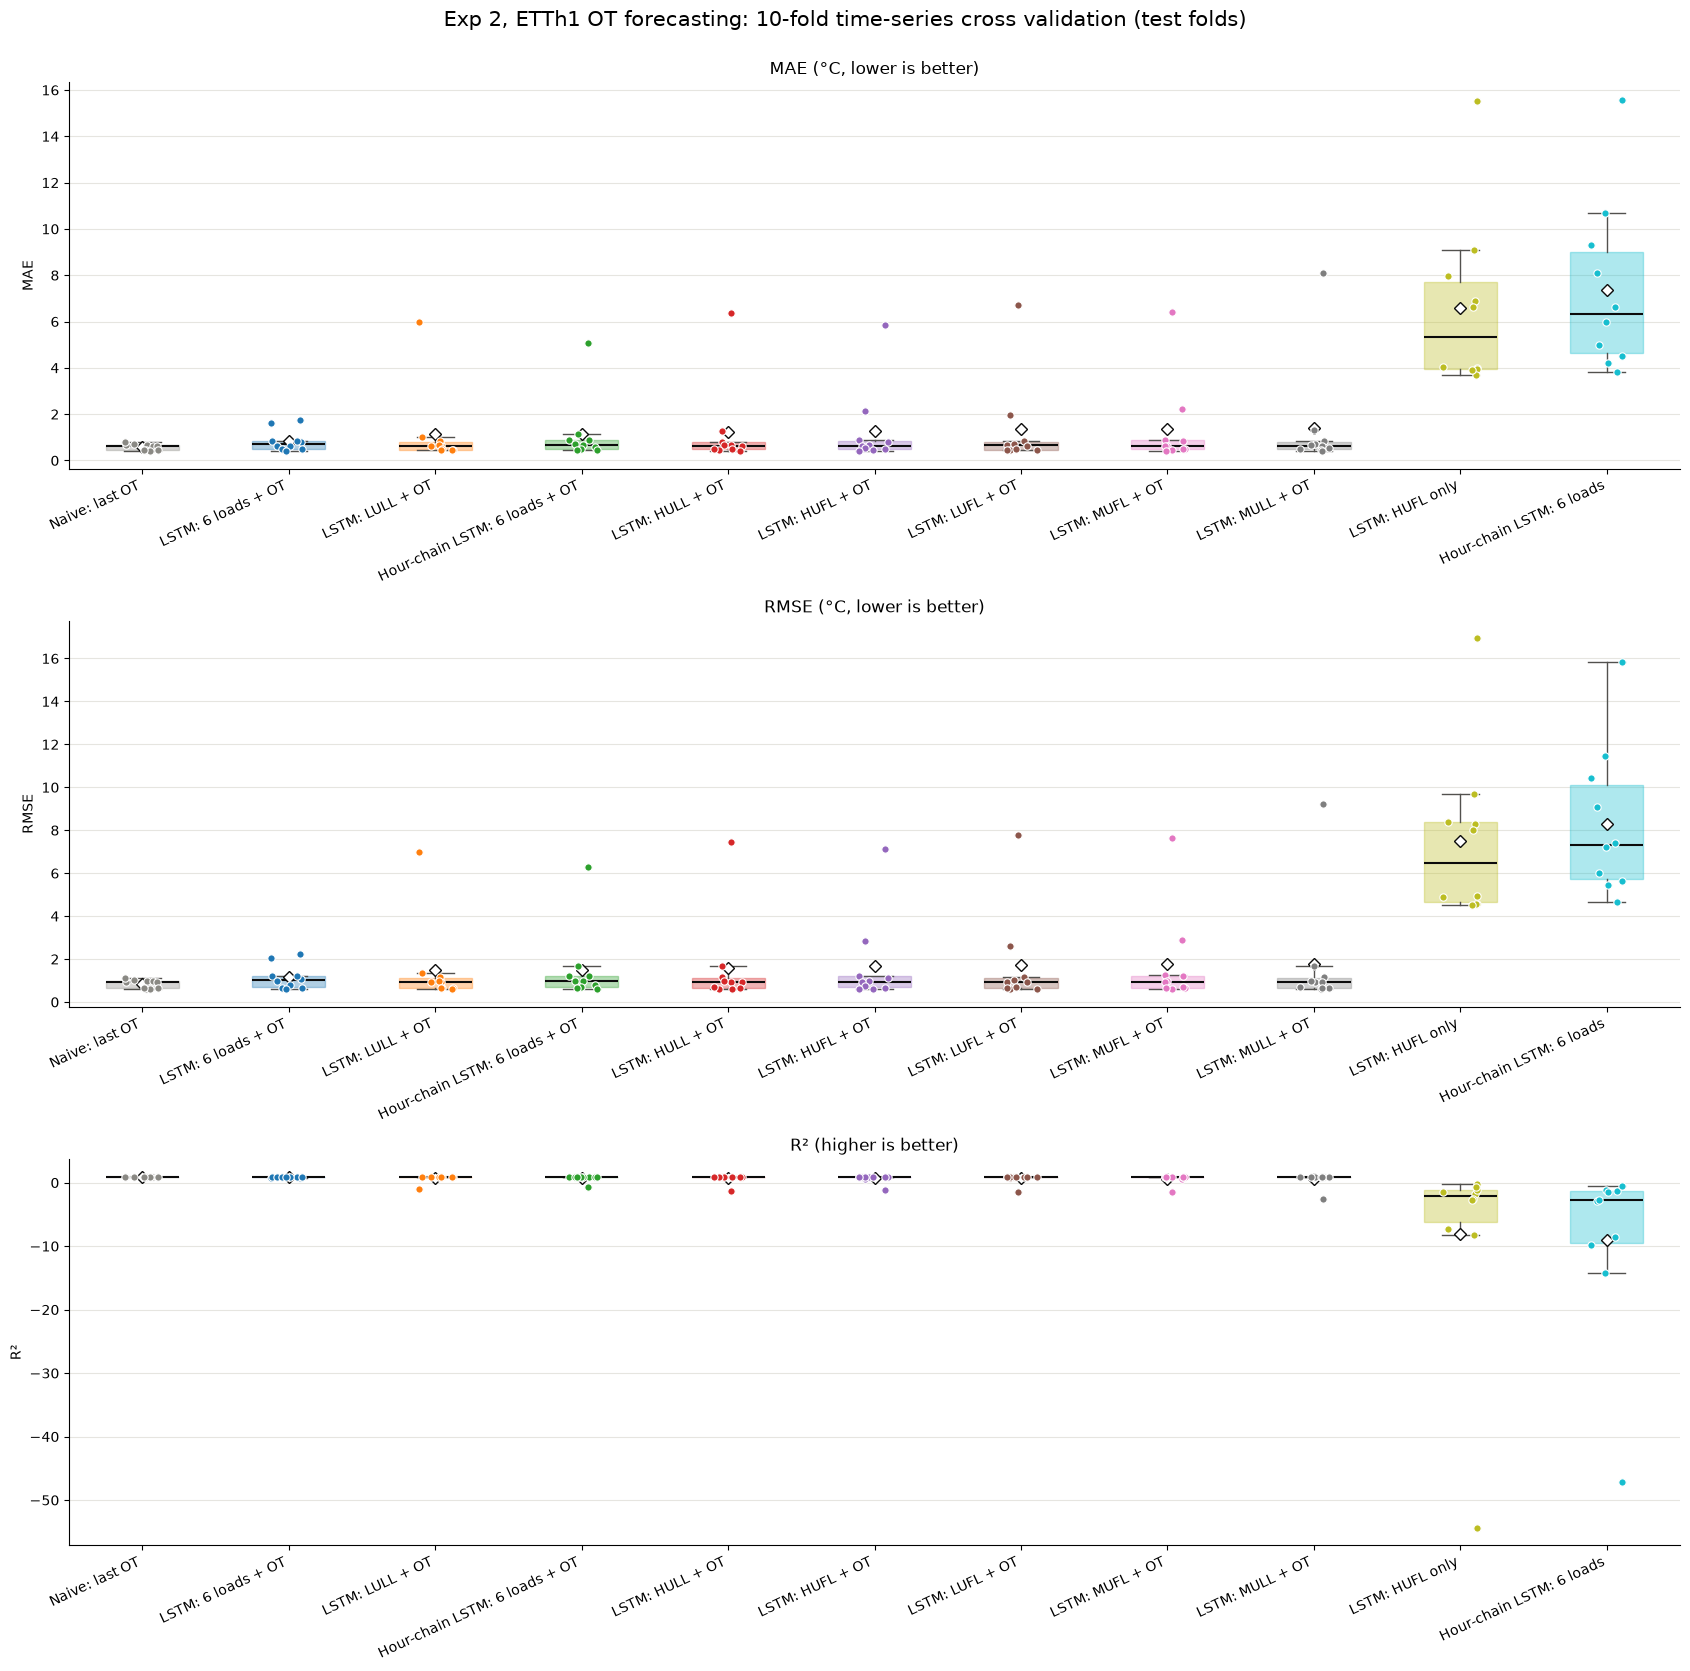

In [40]:
ett_order = list(ett_summary.index)                       # best (lowest RMSE) first
palette = plt.get_cmap("tab10").colors
ETT_COLORS = {n: palette[i % 10] for i, n in enumerate([m for m in ett_order if m != "Naive: last OT"])}
ETT_COLORS["Naive: last OT"] = "#8a8984"
ett_sorted = {n: ett_results[n] for n in ett_order}

fig, axes = plt.subplots(3, 1, figsize=(17, 17))
for ax, (metric, title) in zip(axes, [("MAE", "MAE (°C, lower is better)"), ("RMSE", "RMSE (°C, lower is better)"),
                                      ("R2", "R² (higher is better)")]):
    multi_boxplot(ax, ett_sorted, ETT_COLORS, metric, title, ylabel=title.split(" (")[0])
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
fig.suptitle(f"Exp 2, ETTh1 OT forecasting: {n_folds}-fold time-series cross validation (test folds)", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(os.path.join(output_dir, "boxplot_exp2_ett.png"), dpi=150, bbox_inches="tight")
plt.show()

### Zoomed View: Models with Past OT as Input (+ naive baseline)

The two models without past OT have errors of 4–17 °C, which squashes the scale above. Here only the models that see past OT are shown, on a zoomed axis. Fold-1 points above the axis limit are marked with ▲ and their value.


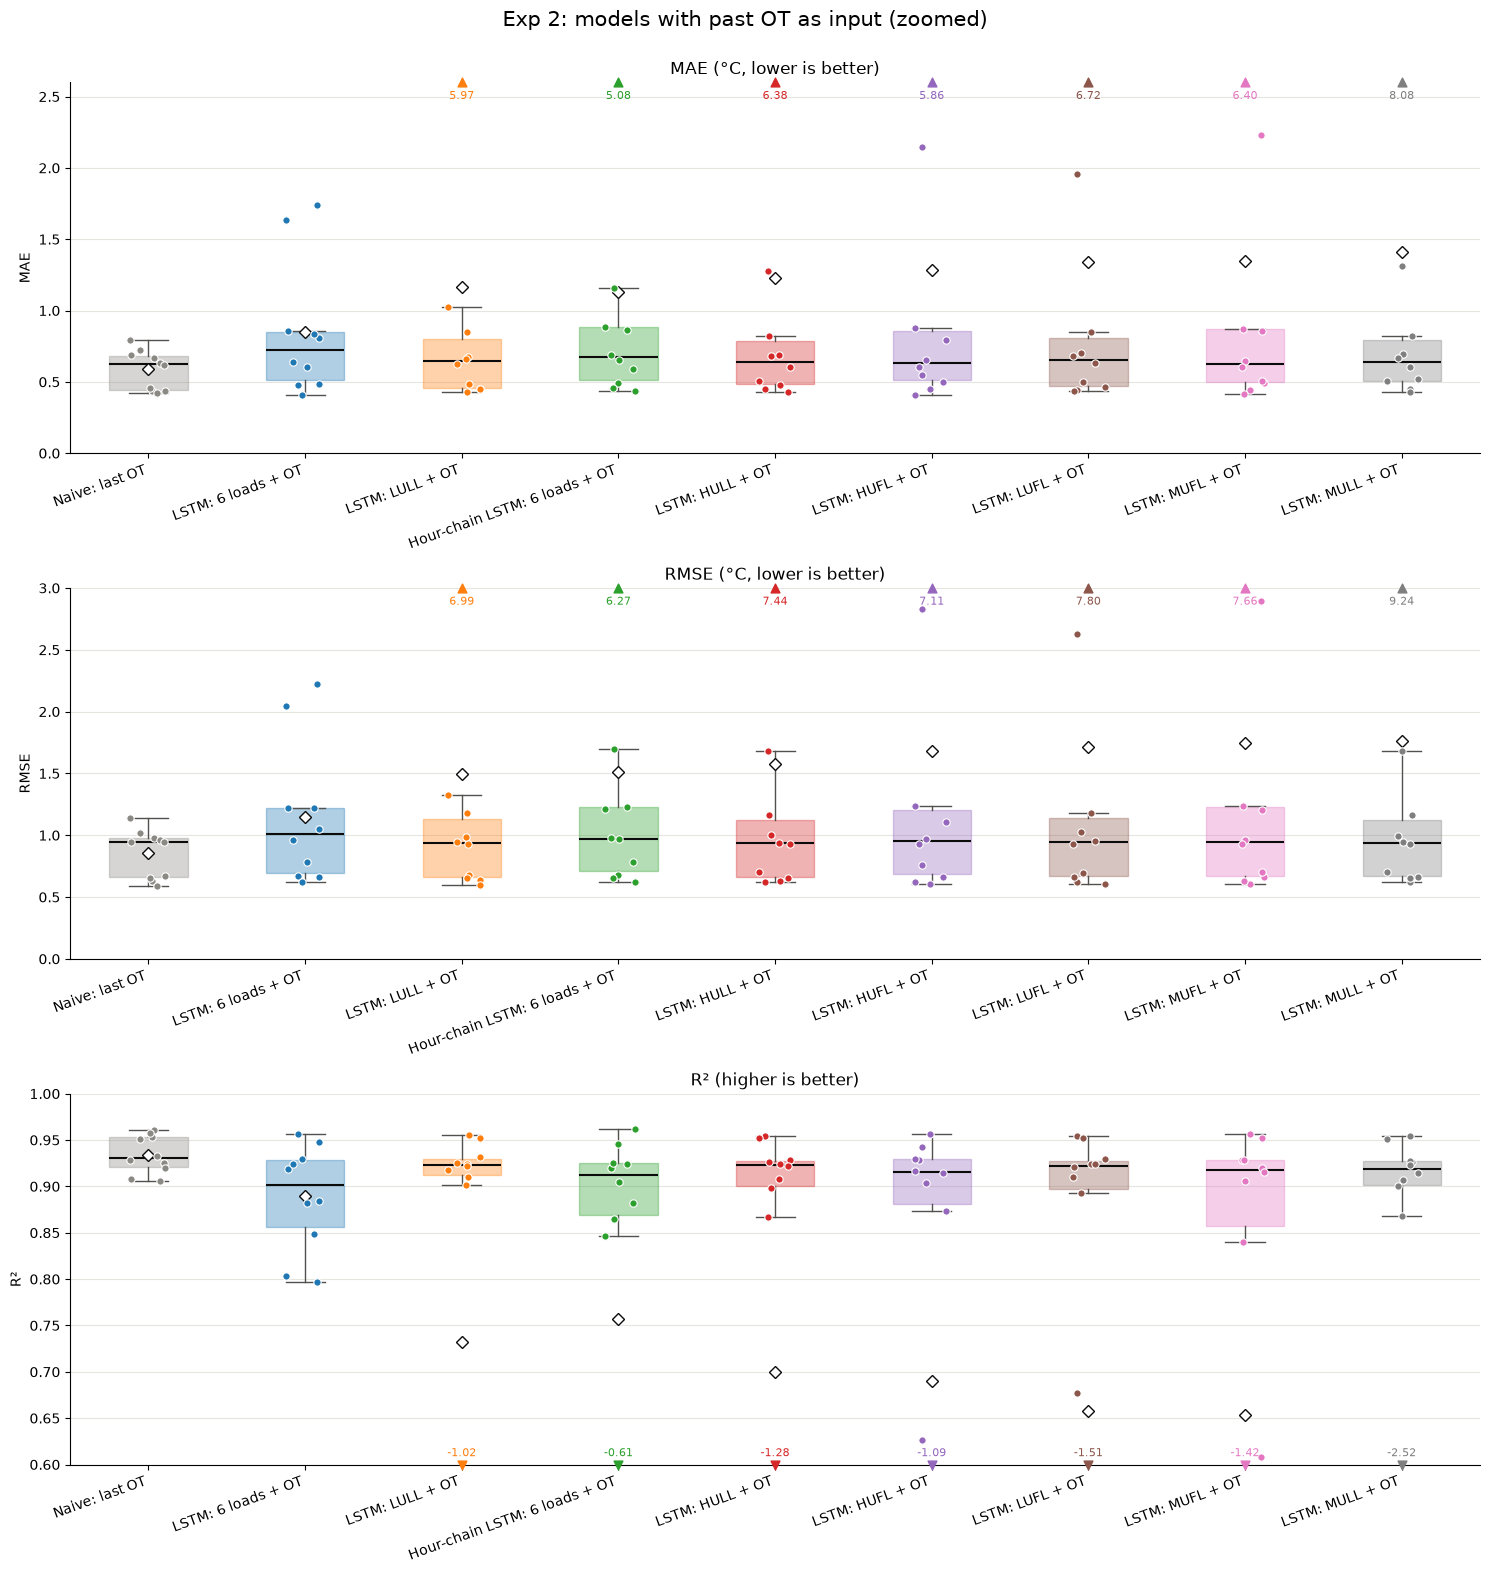

In [41]:
with_ot = {n: ett_results[n] for n in ett_order if "OT" in n.split(":")[1]}
limits = {"MAE": (0, 2.6), "RMSE": (0, 3.0), "R2": (0.6, 1.0)}
fig, axes = plt.subplots(3, 1, figsize=(15, 16))
for ax, (metric, title) in zip(axes, [("MAE", "MAE (°C, lower is better)"), ("RMSE", "RMSE (°C, lower is better)"),
                                      ("R2", "R² (higher is better)")]):
    multi_boxplot(ax, with_ot, ETT_COLORS, metric, title, ylabel=title.split(" (")[0])
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
    lo, hi = limits[metric]
    ax.set_ylim(lo, hi)
    for i, n in enumerate(with_ot, start=1):           # mark points that fall outside the zoomed axis
        for v in with_ot[n][metric].values:
            if v > hi or v < lo:
                y = hi if v > hi else lo
                ax.annotate(f"{v:.2f}", (i, y), xytext=(0, -12 if v > hi else 6), textcoords="offset points",
                            ha="center", fontsize=8, color=ETT_COLORS[n])
                ax.scatter([i], [y], marker="^" if v > hi else "v", color=ETT_COLORS[n], s=40, clip_on=False, zorder=4)
fig.suptitle("Exp 2: models with past OT as input (zoomed)", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(os.path.join(output_dir, "boxplot_exp2_ett_with_ot_zoom.png"), dpi=150, bbox_inches="tight")
plt.show()


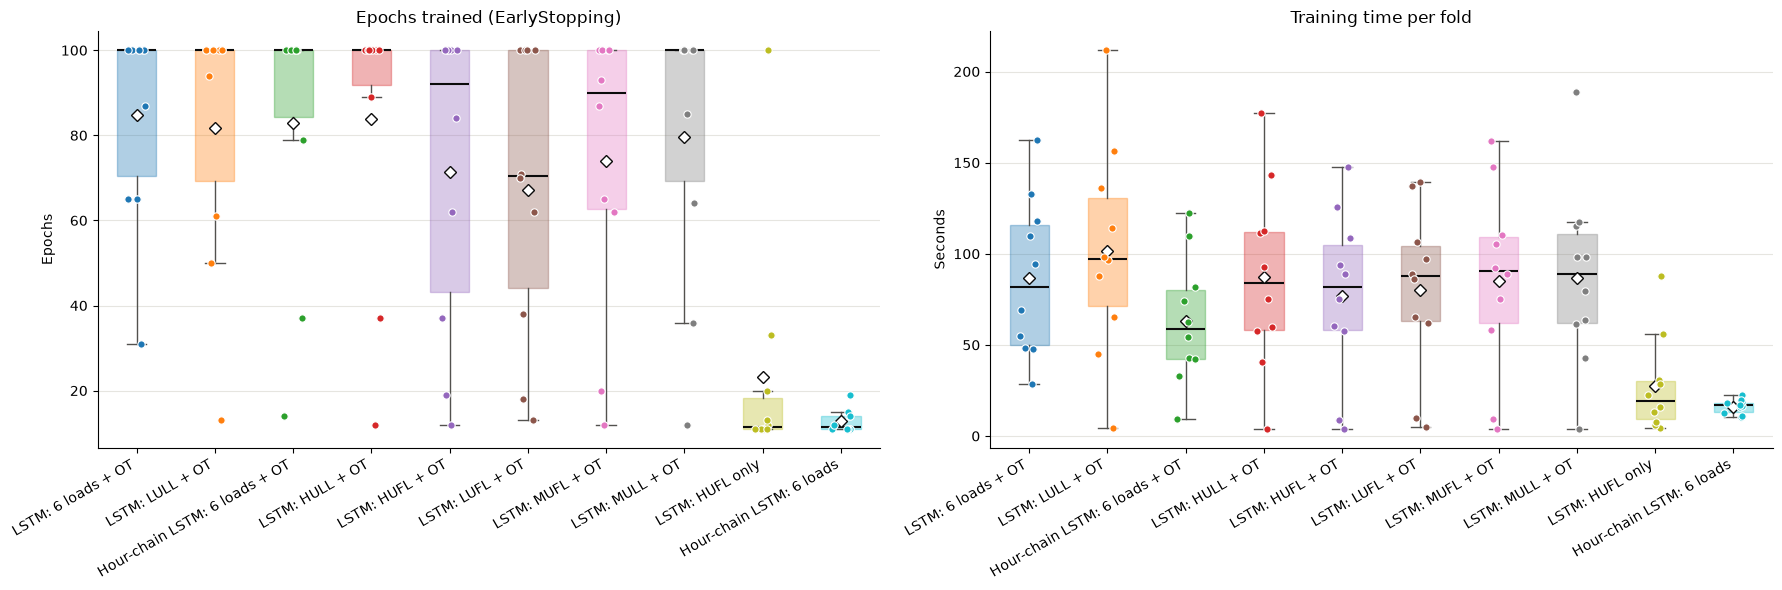

In [42]:
trained = {n: ett_sorted[n] for n in ett_order if n != "Naive: last OT"}
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
multi_boxplot(axes[0], trained, ETT_COLORS, "epochs_trained", "Epochs trained (EarlyStopping)", ylabel="Epochs")
multi_boxplot(axes[1], trained, ETT_COLORS, "train_time_s", "Training time per fold", ylabel="Seconds")
for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "boxplot_exp2_training_cost.png"), dpi=150, bbox_inches="tight")
plt.show()

### RMSE per Fold

Each fold is a different stretch of time, so some folds are harder for every model (for example seasons with fast temperature changes, or test periods that look unlike anything earlier in the training data). The early folds also have much less training data.

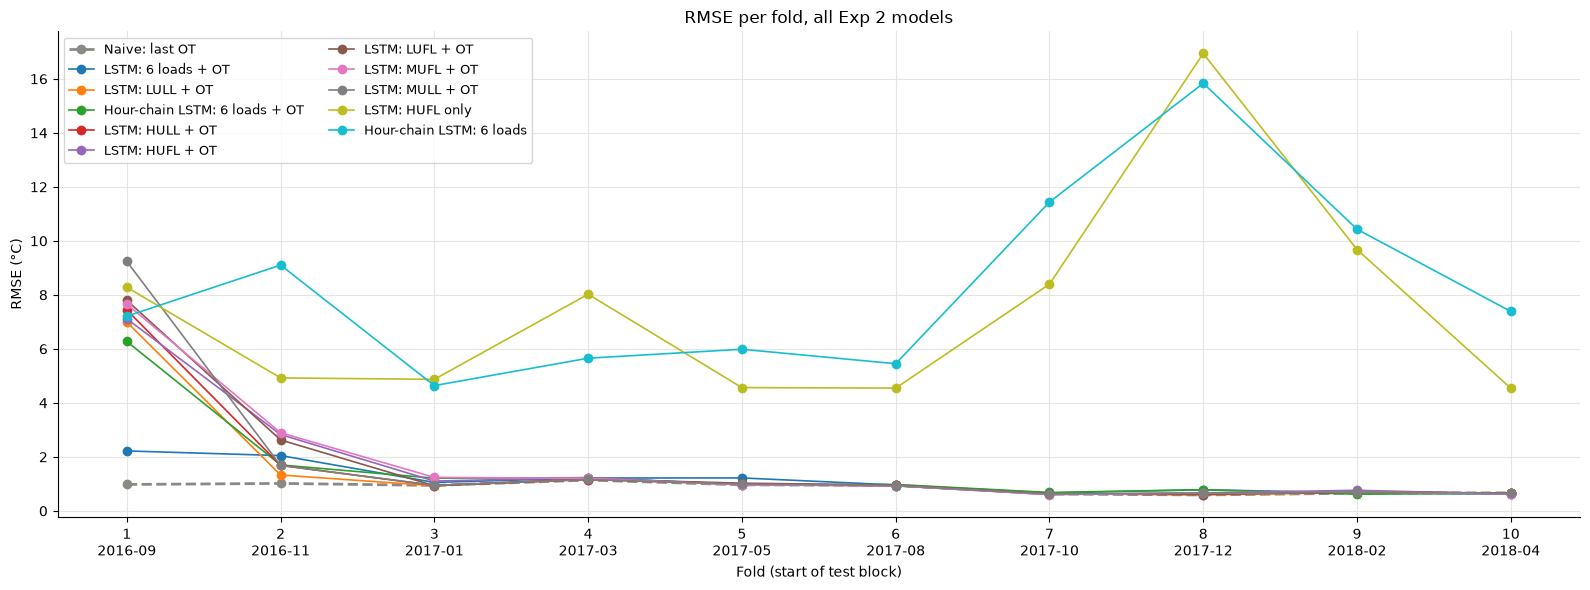

In [43]:
fold_ids_ett = np.arange(1, n_folds + 1)
fig, ax = plt.subplots(figsize=(16, 6))
for n in ett_order:
    ax.plot(fold_ids_ett, ett_results[n]["RMSE"], marker="o", linewidth=2 if n == ett_order[0] else 1.2,
            linestyle="--" if n == "Naive: last OT" else "-", color=ETT_COLORS[n], label=n)
ax.set_xticks(fold_ids_ett,
              [f"{k}\n{ett['date'].iloc[te[0]][:7]}" for k, (_, te) in zip(fold_ids_ett, ett_folds)])
ax.set_xlabel("Fold (start of test block)"); ax.set_ylabel("RMSE (°C)")
ax.set_title("RMSE per fold, all Exp 2 models")
ax.legend(ncol=2, fontsize=9); ax.grid(color="#e6e5e0", linewidth=0.8)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "fold_by_fold_exp2_rmse.png"), dpi=150, bbox_inches="tight")
plt.show()

### Statistical Significance

* **Friedman test** over all 10 Exp 2 models (naive reference excluded).
* **Paired t-test / Wilcoxon** of the best model (lowest mean RMSE) against every other model, and against the naive baseline.

In [44]:
ett_models_only = [n for n in ett_order if n != "Naive: last OT"]
for metric in ["MAE", "RMSE", "R2"]:
    p = stats.friedmanchisquare(*[ett_results[n][metric].values for n in ett_models_only]).pvalue
    print(f"Friedman test, {metric:<4}: p = {p:.4g}  ->  {'models differ' if p < 0.05 else 'no significant difference'}")

best_ett = ett_models_only[0]
print(f"\nBest model by mean RMSE: {best_ett}\n")
rows_ = []
for n in ett_order:
    if n == best_ett:
        continue
    for metric in ["MAE", "RMSE", "R2"]:
        va, vb = ett_results[n][metric].values, ett_results[best_ett][metric].values
        d = vb - va
        t_p = stats.ttest_rel(vb, va).pvalue
        try:
            w_p = stats.wilcoxon(vb, va).pvalue
        except ValueError:
            w_p = np.nan
        better = (d > 0).sum() if metric == "R2" else (d < 0).sum()
        rows_.append({"other model": n, "metric": metric, "best mean": vb.mean(), "other mean": va.mean(),
                      "mean diff (best − other)": d.mean(), "folds where best is better": f"{better}/{n_folds}",
                      "paired t-test p": t_p, "Wilcoxon p": w_p,
                      "significant (p<0.05)": "yes" if t_p < 0.05 and (np.isnan(w_p) or w_p < 0.05) else "no"})
ett_sig = pd.DataFrame(rows_).set_index(["other model", "metric"])
ett_sig.to_csv(os.path.join(output_dir, "cv_significance_exp2_ett.csv"))
ett_sig.round(4)

Friedman test, MAE : p = 7.622e-06  ->  models differ
Friedman test, RMSE: p = 3.602e-06  ->  models differ
Friedman test, R2  : p = 4.919e-06  ->  models differ

Best model by mean RMSE: LSTM: 6 loads + OT



best mean  other mean  \
other model                   metric                          
Naive: last OT                MAE        0.8489      0.5873   
                              RMSE       1.1453      0.8527   
                              R2         0.8892      0.9343   
LSTM: LULL + OT               MAE        0.8489      1.1619   
                              RMSE       1.1453      1.4926   
                              R2         0.8892      0.7323   
Hour-chain LSTM: 6 loads + OT MAE        0.8489      1.1308   
                              RMSE       1.1453      1.5098   
                              R2         0.8892      0.7570   
LSTM: HULL + OT               MAE        0.8489      1.2303   
                              RMSE       1.1453      1.5761   
                              R2         0.8892      0.6998   
LSTM: HUFL + OT               MAE        0.8489      1.2852   
                              RMSE       1.1453      1.6838   
                              R2         0.8892      0.6905   
LSTM: LUFL + OT               MAE        0.8489      1.3376   
                              RMSE       1.1453      1.7103   
                              R2         0.8892      0.6578   
LSTM: MUFL + OT               MAE        0.8489      1.3470   
                              RMSE       1.1453      1.7481   
                              R2         0.8892      0.6539   
LSTM: MULL + OT               MAE        0.8489      1.4078   
                              RMSE       1.1453      1.7597   
                              R2         0.8892      0.5753   
LSTM: HUFL only               MAE        0.8489      6.5662   
                              RMSE       1.1453      7.4772   
                              R2         0.8892     -8.0442   
Hour-chain LSTM: 6 loads      MAE        0.8489      7.3797   
                              RMSE       1.1453      8.3132   
                              R2         0.8892     -8.9642   

                                      mean diff (best − other)  \
other model                   metric                             
Naive: last OT                MAE                       0.2616   
                              RMSE                      0.2926   
                              R2                       -0.0451   
LSTM: LULL + OT               MAE                      -0.3130   
                              RMSE                     -0.3473   
                              R2                        0.1569   
Hour-chain LSTM: 6 loads + OT MAE                      -0.2820   
                              RMSE                     -0.3646   
                              R2                        0.1322   
LSTM: HULL + OT               MAE                      -0.3815   
                              RMSE                     -0.4308   
                              R2                        0.1895   
LSTM: HUFL + OT               MAE                      -0.4363   
                              RMSE                     -0.5385   
                              R2                        0.1987   
LSTM: LUFL + OT               MAE                      -0.4887   
                              RMSE                     -0.5650   
                              R2                        0.2314   
LSTM: MUFL + OT               MAE                      -0.4981   
                              RMSE                     -0.6028   
                              R2                        0.2353   
LSTM: MULL + OT               MAE                      -0.5590   
                              RMSE                     -0.6144   
                              R2                        0.3140   
LSTM: HUFL only               MAE                      -5.7173   
                              RMSE                     -6.3319   
                              R2                        8.9335   
Hour-chain LSTM: 6 loads      MAE                      -6.5308   
                              RMSE       

### Out-of-fold Predictions vs Actual OT

Joining the 10 test blocks gives a prediction for most of the series (everything after the first block). Shown for the best model and for the best model without past OT as input.

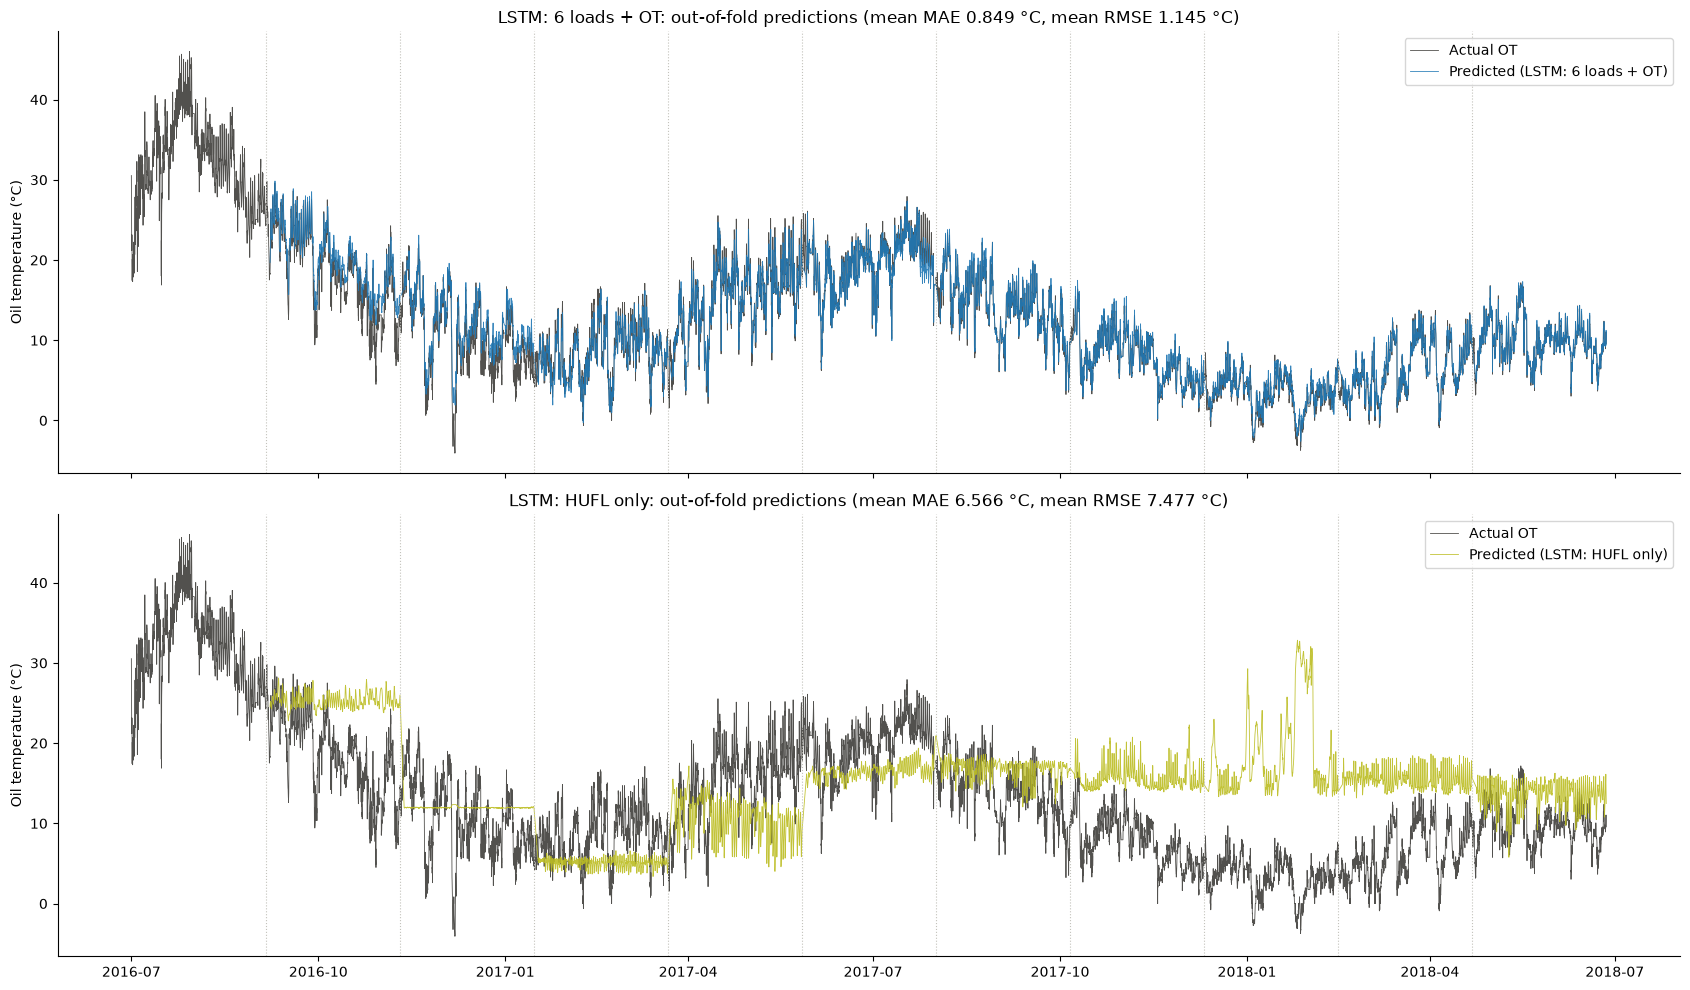

In [45]:
no_ot = [n for n in ett_models_only if "OT" not in n.split(":")[1]]
show = [best_ett] + ([no_ot[0]] if no_ot else [])
dates = pd.to_datetime(ett["date"])
fig, axes = plt.subplots(len(show), 1, figsize=(17, 5 * len(show)), sharex=True)
axes = np.atleast_1d(axes)
for ax, n in zip(axes, show):
    m = ~np.isnan(ett_oof[n])
    ax.plot(dates, ett["OT"], color="#52514e", linewidth=0.6, label="Actual OT")
    ax.plot(dates[m], ett_oof[n][m], color=ETT_COLORS[n], linewidth=0.6, alpha=0.9, label=f"Predicted ({n})")
    for _, te in ett_folds:
        ax.axvline(dates.iloc[te[0]], color="#c3c2bb", linewidth=0.8, linestyle=":")
    r = ett_results[n]
    ax.set_title(f"{n}: out-of-fold predictions (mean MAE {r['MAE'].mean():.3f} °C, mean RMSE {r['RMSE'].mean():.3f} °C)")
    ax.set_ylabel("Oil temperature (°C)"); ax.legend(loc="upper right")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "oof_predictions_exp2.png"), dpi=150, bbox_inches="tight")
plt.show()

### Exp 2: Hold-out Test (last 20% in time)

Each Exp 2 model is trained once on the **first 80%** of the series (the last 10% of that is the EarlyStopping validation set) and tested on the **last 20%** (about 3,484 hours, Feb–Jun 2018). This is the same test period as the original Exp 2 60:20:20 split. The naive baseline is scored on the same hours.

In [46]:
n_hold = int(len(ett) * holdout_size)
ett_train_idx, ett_hold_idx = np.arange(len(ett) - n_hold), np.arange(len(ett) - n_hold, len(ett))
print(f"ETTh1: train {ett['date'].iloc[0]} -> {ett['date'].iloc[ett_train_idx[-1]]} ({len(ett_train_idx)} h), "
      f"hold-out {ett['date'].iloc[ett_hold_idx[0]]} -> {ett['date'].iloc[-1]} ({len(ett_hold_idx)} h)")

ett_hold, ett_hold_pred = {}, {}
for name, cfg in EXP2_MODELS.items():
    def fn(cfg=cfg):
        row, pred_rows, pred, _ = ett_fold(cfg, 99, ett_train_idx, ett_hold_idx)
        return row, np.stack([pred_rows.astype("float64"), pred.astype("float64")])
    ett_hold[name], ett_hold_pred[name] = run_holdout(cfg["tag"], fn)

rows_n = ett_hold_idx[seq_length:]
t_, p_ = ot[rows_n], ot[rows_n - 1]
ett_hold["Naive: last OT"] = {"MAE": mean_absolute_error(t_, p_), "RMSE": float(np.sqrt(mean_squared_error(t_, p_))),
                               "R2": r2_score(t_, p_), "train_time_s": 0.0, "epochs_trained": 0}
ett_hold_pred["Naive: last OT"] = np.stack([rows_n.astype("float64"), p_.astype("float64")])

ett_hold_table = pd.DataFrame({
    "CV MAE": [f"{ett_results[n]['MAE'].mean():.4f} ± {ett_results[n]['MAE'].std():.4f}" for n in ett_order],
    "CV RMSE": [f"{ett_results[n]['RMSE'].mean():.4f} ± {ett_results[n]['RMSE'].std():.4f}" for n in ett_order],
    "hold-out MAE": [ett_hold[n]["MAE"] for n in ett_order],
    "hold-out RMSE": [ett_hold[n]["RMSE"] for n in ett_order],
    "hold-out R2": [ett_hold[n]["R2"] for n in ett_order],
    "epochs": [ett_hold[n]["epochs_trained"] for n in ett_order],
}, index=ett_order).sort_values("hold-out RMSE")
ett_hold_table.to_csv(os.path.join(output_dir, "holdout_summary_exp2_ett.csv"))
ett_hold_table.round(4)

ETTh1: train 2016-07-01 00:00:00 -> 2018-02-01 15:00:00 (13936 h), hold-out 2018-02-01 16:00:00 -> 2018-06-26 19:00:00 (3484 h)


exp2_lstm_hufl_ot: hold-out done in 78s


exp2_lstm_hull_ot: hold-out done in 85s


exp2_lstm_mufl_ot: hold-out done in 78s


exp2_lstm_mull_ot: hold-out done in 56s


exp2_lstm_lufl_ot: hold-out done in 60s


... (2 outputs left out)

exp2_chain_all_ot: hold-out done in 99s


exp2_lstm_hufl: hold-out done in 18s


exp2_chain_all: hold-out done in 16s


,CV MAE,CV RMSE,hold-out MAE,hold-out RMSE,hold-out R2,epochs
Hour-chain LSTM: 6 loads + OT,1.1308 ± 1.4045,1.5098 ± 1.7070,0.4520,0.6494,0.9645,100.0
Naive: last OT,0.5873 ± 0.1364,0.8527 ± 0.1970,0.4485,0.6556,0.9632,0.0
LSTM: HULL + OT,1.2303 ± 1.8257,1.5761 ± 2.0858,0.4644,0.6642,0.9622,54.0
LSTM: HUFL + OT,1.2852 ± 1.6870,1.6838 ± 2.0162,0.4750,0.6765,0.9608,48.0
LSTM: MUFL + OT,1.3470 ± 1.8552,1.7481 ± 2.1834,0.4773,0.6785,0.9606,50.0
LSTM: 6 loads + OT,0.8489 ± 0.4692,1.1453 ± 0.5667,0.4908,0.6948,0.9586,32.0
LSTM: LUFL + OT,1.3376 ± 1.9426,1.7103 ± 2.2193,0.4885,0.6961,0.9585,38.0
LSTM: LULL + OT,1.1619 ± 1.7015,1.4926 ± 1.9480,0.4982,0.7096,0.9568,35.0
LSTM: MULL + OT,1.4078 ± 2.3584,1.7597 ± 2.6470,0.5065,0.7222,0.9553,35.0
LSTM: HUFL only,6.5662 ± 3.7092,7.4772 ± 3.8759,8.2494,9.0337,-5.9933,11.0


### Exp 2: Scatter Plots of the Hold-out Forecasts

**Predicted vs actual OT** on the hold-out hours, one panel per model: a perfect forecast lies on the dashed diagonal. The models without past OT form a cloud far from the diagonal. The models with past OT hug it.

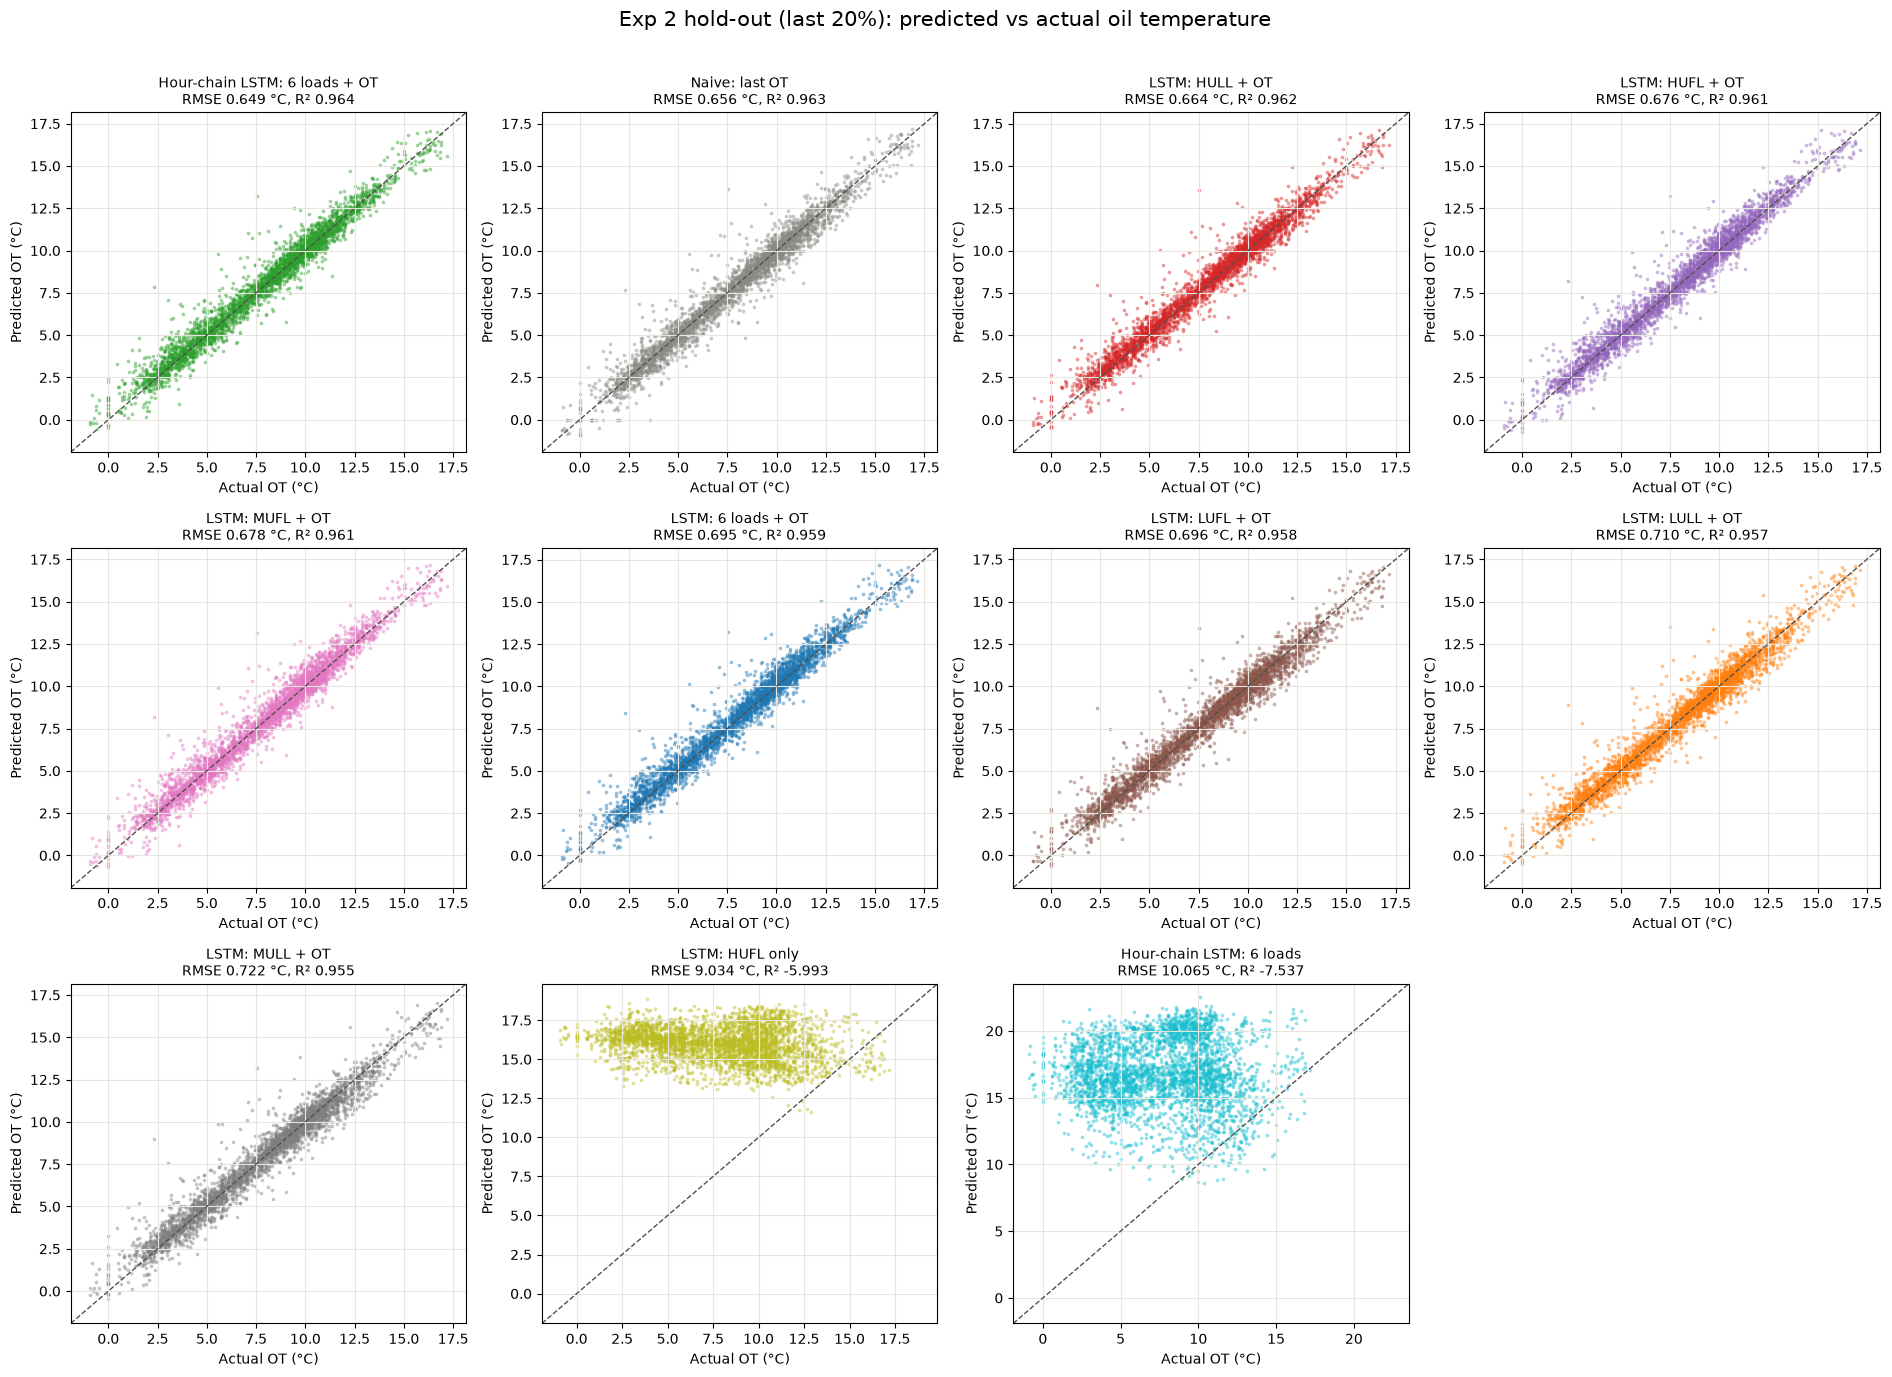

In [47]:
hold_order = list(ett_hold_table.index)
fig, axes = plt.subplots(3, 4, figsize=(19, 14))
for ax, n in zip(axes.ravel(), hold_order):
    rows_p, pred = ett_hold_pred[n][0].astype(int), ett_hold_pred[n][1]
    true = ot[rows_p]
    ax.scatter(true, pred, s=3, alpha=0.35, color=ETT_COLORS[n])
    lim = (min(true.min(), pred.min()) - 1, max(true.max(), pred.max()) + 1)
    ax.plot(lim, lim, color="#52514e", linestyle="--", linewidth=1)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{n}\nRMSE {ett_hold[n]['RMSE']:.3f} °C, R² {ett_hold[n]['R2']:.3f}", fontsize=10)
    ax.set_xlabel("Actual OT (°C)"); ax.set_ylabel("Predicted OT (°C)")
    ax.grid(color="#e6e5e0", linewidth=0.8)
for ax in axes.ravel()[len(hold_order):]:
    ax.axis("off")
fig.suptitle("Exp 2 hold-out (last 20%): predicted vs actual oil temperature", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(os.path.join(output_dir, "scatter_exp2_holdout_pred_vs_actual.png"), dpi=150, bbox_inches="tight")
plt.show()

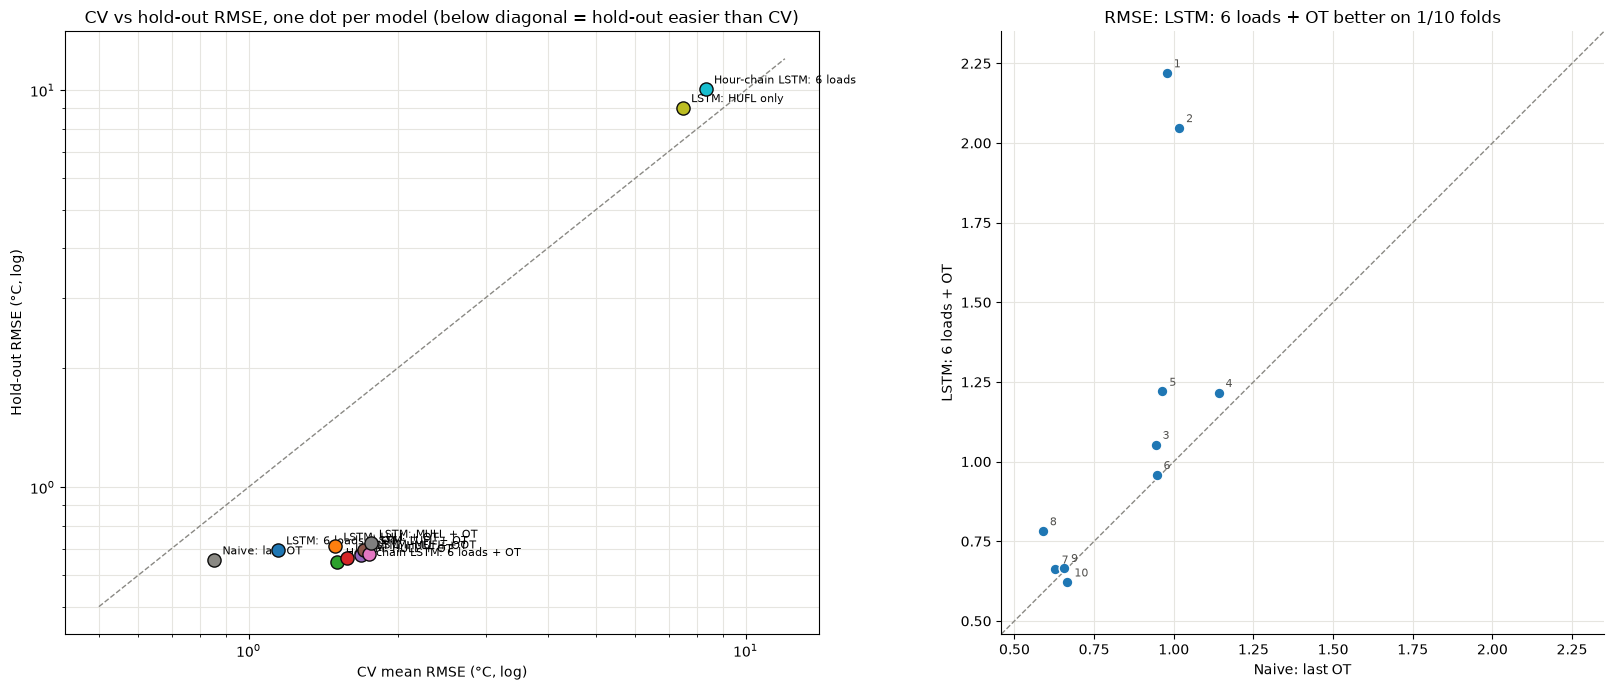

In [48]:
# CV vs hold-out per model (scatter, one dot per model) and fold-by-fold scatter of the best model vs naive
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
ax = axes[0]
for n in ett_order:
    x_, y_ = ett_results[n]["RMSE"].mean(), ett_hold[n]["RMSE"]
    ax.scatter(x_, y_, s=90, color=ETT_COLORS[n], edgecolor="#0b0b0b", zorder=3)
    ax.annotate(n, (x_, y_), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log")
lim = [0.5, 12]
ax.plot(lim, lim, color="#8a8984", linestyle="--", linewidth=1)
ax.set_xlabel("CV mean RMSE (°C, log)"); ax.set_ylabel("Hold-out RMSE (°C, log)")
ax.set_title("CV vs hold-out RMSE, one dot per model (below diagonal = hold-out easier than CV)")
ax.grid(color="#e6e5e0", linewidth=0.8, which="both")
paired_scatter(axes[1], ett_results["Naive: last OT"], ett_results[best_ett], "RMSE", "Naive: last OT", best_ett,
               ETT_COLORS[best_ett], lower_is_better=True)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "scatter_exp2_cv_vs_holdout.png"), dpi=150, bbox_inches="tight")
plt.show()

## Exp 2 Conclusion

In [49]:
print(f"{'Model':<32}{'MAE (°C)':>20}{'RMSE (°C)':>20}{'R2':>20}{'Params':>8}{'s / fold':>10}")
for n in ett_order:
    r = ett_results[n]
    print(f"{n:<32}"
          f"{r['MAE'].mean():>12.4f} ± {r['MAE'].std():.4f}"
          f"{r['RMSE'].mean():>12.4f} ± {r['RMSE'].std():.4f}"
          f"{r['R2'].mean():>12.4f} ± {r['R2'].std():.4f}"
          f"{int(r['n_params'].iloc[0]):>8}{r['train_time_s'].mean():>10.0f}")
print()
s = ett_sig.xs("RMSE", level="metric")
n_sig = (s["significant (p<0.05)"] == "yes").sum()
print(f"Best model: {best_ett}. On RMSE it is significantly better (p < 0.05, both tests) than "
      f"{n_sig} of the {len(s)} other models / baseline:")
for n, r in s.iterrows():
    print(f"  vs {n:<32} diff {r['mean diff (best − other)']:+.4f} °C, t-test p = {r['paired t-test p']:.4g}, "
          f"significant: {r['significant (p<0.05)']}")

Model                                       MAE (°C)           RMSE (°C)                  R2  Params  s / fold
Naive: last OT                        0.5873 ± 0.1364      0.8527 ± 0.1970      0.9343 ± 0.0205       0         0
LSTM: 6 loads + OT                    0.8489 ± 0.4692      1.1453 ± 0.5667      0.8892 ± 0.0570     343        87
LSTM: LULL + OT                       1.1619 ± 1.7015      1.4926 ± 1.9480      0.7323 ± 0.6145     223       102
Hour-chain LSTM: 6 loads + OT         1.1308 ± 1.4045      1.5098 ± 1.7070      0.7570 ± 0.4799    2743        63
LSTM: HULL + OT                       1.2303 ± 1.8257      1.5761 ± 2.0858      0.6998 ± 0.6970     223        87
LSTM: HUFL + OT                       1.2852 ± 1.6870      1.6838 ± 2.0162      0.6905 ± 0.6318     223        77
LSTM: LUFL + OT                       1.3376 ± 1.9426      1.7103 ± 2.2193      0.6578 ± 0.7644     223        80
LSTM: MUFL + OT                       1.3470 ± 1.8552      1.7481 ± 2.1834      0.6539 ± 0.

# Final Conclusion: All Experiments (10-fold CV and hold-out)

In [50]:
def block(title, res_dict, hold_dict, cols):
    print(f"===== {title} =====")
    head = "".join(f"{'CV ' + c:>22}{'hold-out':>10}" for c, _ in cols)
    print(f"{'Model':<32}{head}")
    for n in res_dict:
        line_ = f"{n:<32}"
        for c, _ in cols:
            r = res_dict[n][c]
            line_ += f"{r.mean():>13.4f} ± {r.std():.4f}{hold_dict[n][c]:>10.4f}"
        print(line_)
    print()

block("Exp 3: US Airline Tweets", results, tweet_hold, [("accuracy", ""), ("f1_macro", "")])
block("Exp 1: MNIST", mnist_results, mnist_hold, [("accuracy", ""), ("f1_macro", "")])
block("Exp 2: ETTh1 (°C)", {n: ett_results[n] for n in ett_order}, ett_hold, [("MAE", ""), ("RMSE", "")])

print(f"Exp 3: LSTM + Attention vs LSTM: macro F1 diff {significance.loc['Macro F1', 'mean diff (Attn − LSTM)']:+.4f}, "
      f"paired t-test p = {significance.loc['Macro F1', 'paired t-test p']:.3g}")
r = mnist_sig.xs("Macro F1", level="metric").iloc[0]
print(f"Exp 1: CNN vs MLP: macro F1 diff {r['mean diff (model − MLP)']:+.4f}, paired t-test p = {r['paired t-test p']:.3g}")
print(f"Exp 2: best model {best_ett}; vs naive RMSE diff "
      f"{ett_sig.loc[('Naive: last OT', 'RMSE'), 'mean diff (best − other)']:+.4f} °C, "
      f"p = {ett_sig.loc[('Naive: last OT', 'RMSE'), 'paired t-test p']:.3g}")

===== Exp 3: US Airline Tweets =====
Model                                      CV accuracy  hold-out           CV f1_macro  hold-out
LSTM                                   0.8044 ± 0.0167    0.7970       0.7348 ± 0.0245    0.7163
LSTM + Attention                       0.8057 ± 0.0167    0.7983       0.7354 ± 0.0270    0.7177

===== Exp 1: MNIST =====
Model                                      CV accuracy  hold-out           CV f1_macro  hold-out
MLP                                    0.9721 ± 0.0039    0.9722       0.9719 ± 0.0039    0.9720
CNN                                    0.9885 ± 0.0020    0.9885       0.9884 ± 0.0020    0.9885

===== Exp 2: ETTh1 (°C) =====
Model                                           CV MAE  hold-out               CV RMSE  hold-out
Naive: last OT                         0.5873 ± 0.1364    0.4485       0.8527 ± 0.1970    0.6556
LSTM: 6 loads + OT                     0.8489 ± 0.4692    0.4908       1.1453 ± 0.5667    0.6948
LSTM: LULL + OT                  